IMPORTING REQUIRED LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings("ignore")

DATA LOADING

In [2]:
# File path
file_path = r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\FINAL DATA\Final Data for Model.xlsx"

# Import dataset
df = pd.read_excel(file_path, sheet_name="Sheet1")

# Display first five rows
df.head()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Left Shoulder Type,Right Shoulder Width,Right Shoulder Type,IRI
0,1,57.0,1.27,inf,5.5,0.9,Gravel,0.9,Gravel,3.70
1,2,33.0,2.92,46.0,5.5,0.9,Gravel,0.9,Gravel,4.51
2,3,43.0,7.97,inf,5.5,0.9,Gravel,0.9,Gravel,4.39
3,4,48.0,2.07,inf,5.5,0.9,Gravel,0.9,Gravel,4.69
4,5,36.0,1.21,16.0,5.5,0.9,Gravel,0.9,Gravel,5.57


INITIAL INSPECTION OF DATA

In [3]:
df.shape

(165, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SN                    165 non-null    int64  
 1   V85 Speed             165 non-null    float64
 2   Gradient              165 non-null    float64
 3   Radius of Curve       165 non-null    float64
 4   Carriageway Width     165 non-null    float64
 5   Left Shoulder Width   165 non-null    float64
 6   Left Shoulder Type    165 non-null    str    
 7   Right Shoulder Width  165 non-null    float64
 8   Right Shoulder Type   165 non-null    str    
 9   IRI                   165 non-null    float64
dtypes: float64(7), int64(1), str(2)
memory usage: 13.0 KB


In [5]:
df.describe()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI
count,165.000000,165.000000,165.000000,165.0,165.000000,165.000000,165.000000,165.000000
mean,89.145455,44.525758,4.100955,inf,6.323788,0.622606,0.628545,5.922667
std,50.827213,9.485801,2.498089,NaN,0.894131,0.407672,0.397181,2.636332
min,1.000000,25.000000,0.070000,15.0,4.700000,0.000000,0.000000,2.150000
25%,47.000000,37.000000,1.850000,35.0,5.500000,0.300000,0.380000,3.700000
50%,89.000000,44.000000,4.090000,75.0,7.000000,0.750000,0.750000,5.350000
75%,132.000000,50.000000,6.000000,NaN,7.000000,1.000000,1.000000,8.340000
max,175.000000,67.250000,11.085000,inf,8.000000,1.130000,1.180000,12.050000


DATA CLEANING AND PREPARATION

Missing Value Check

In [6]:
df.isnull().sum()

SN                      0
V85 Speed               0
Gradient                0
Radius of Curve         0
Carriageway Width       0
Left Shoulder Width     0
Left Shoulder Type      0
Right Shoulder Width    0
Right Shoulder Type     0
IRI                     0
dtype: int64

Cleaning Categorical Variables


In [7]:
df["Left Shoulder Type"] = df["Left Shoulder Type"].str.strip().str.lower().str.capitalize()
df["Right Shoulder Type"] = df["Right Shoulder Type"].str.strip().str.lower().str.capitalize()

Encoding

In [8]:
df_encoded = pd.get_dummies(
    df,
    columns=["Left Shoulder Type", "Right Shoulder Type"],
    drop_first=True,
    dtype=int
)

Putting Radius of Curve of Tangent Section Infinity as 1500

In [9]:
# Identify tangent sections
tangent_mask = (
    df_encoded["Radius of Curve"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["infinity", "inf", "∞"])
)

# Count tangent sections
print("Number of tangent sections:", tangent_mask.sum())

# Replace infinity with 1500
df_encoded.loc[tangent_mask, "Radius of Curve"] = 1500

# Convert radius column to numeric
df_encoded["Radius of Curve"] = pd.to_numeric(
    df_encoded["Radius of Curve"],
    errors="raise"
)

# Verify replacement
print("Infinity values remaining:",
      np.isinf(df_encoded["Radius of Curve"]).sum())

df_encoded.head()

Number of tangent sections: 45
Infinity values remaining: 0


,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI,Left Shoulder Type_Gravel,Left Shoulder Type_Paved,Right Shoulder Type_Gravel,Right Shoulder Type_Paved
0,1,57.0,1.27,1500.0,5.5,0.9,0.9,3.70,1,0,1,0
1,2,33.0,2.92,46.0,5.5,0.9,0.9,4.51,1,0,1,0
2,3,43.0,7.97,1500.0,5.5,0.9,0.9,4.39,1,0,1,0
3,4,48.0,2.07,1500.0,5.5,0.9,0.9,4.69,1,0,1,0
4,5,36.0,1.21,16.0,5.5,0.9,0.9,5.57,1,0,1,0


Variance Inflation Factor(VIF for Multicollinearity Check)


In [10]:
# Select independent variables for VIF

X_vif = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Left Shoulder Width",
        "Right Shoulder Width",
        "IRI",
        "Left Shoulder Type_Gravel",
        "Left Shoulder Type_Paved",
        "Right Shoulder Type_Gravel",
        "Right Shoulder Type_Paved"
    ]
]

# Convert to float
X_vif = X_vif.astype(float)

# Add constant
X_vif_const = sm.add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif_const.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_const.values, i)
    for i in range(X_vif_const.shape[1])
]

# Display results
display(vif_data.round(3))

,Feature,VIF
0,const,104.455
1,Gradient,1.129
2,Radius of Curve,1.111
3,Carriageway Width,1.259
4,Left Shoulder Width,7.359
5,Right Shoulder Width,5.800
6,IRI,1.829
7,Left Shoulder Type_Gravel,8.843
8,Left Shoulder Type_Paved,8.470
9,Right Shoulder Type_Gravel,6.547


Average Shoulder Width

In [11]:
# Calculate Average Shoulder Width

df_encoded["Average Shoulder Width"] = (
    df_encoded["Left Shoulder Width"] +
    df_encoded["Right Shoulder Width"]
) / 2

# Display updated dataset
df_encoded.head()

,SN,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Left Shoulder Width,Right Shoulder Width,IRI,Left Shoulder Type_Gravel,Left Shoulder Type_Paved,Right Shoulder Type_Gravel,Right Shoulder Type_Paved,Average Shoulder Width
0,1,57.0,1.27,1500.0,5.5,0.9,0.9,3.70,1,0,1,0,0.9
1,2,33.0,2.92,46.0,5.5,0.9,0.9,4.51,1,0,1,0,0.9
2,3,43.0,7.97,1500.0,5.5,0.9,0.9,4.39,1,0,1,0,0.9
3,4,48.0,2.07,1500.0,5.5,0.9,0.9,4.69,1,0,1,0,0.9
4,5,36.0,1.21,16.0,5.5,0.9,0.9,5.57,1,0,1,0,0.9


Recalculating VIF

In [12]:
# Select independent variables for VIF

X_vif = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI",
        "Left Shoulder Type_Gravel",
        "Left Shoulder Type_Paved",
        "Right Shoulder Type_Gravel",
        "Right Shoulder Type_Paved"
    ]
]

# Convert to float
X_vif = X_vif.astype(float)

# Add constant
X_vif_const = sm.add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif_const.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_const.values, i)
    for i in range(X_vif_const.shape[1])
]

# Display VIF results
display(vif_data.round(3))

,Feature,VIF
0,const,101.331
1,Gradient,1.118
2,Radius of Curve,1.111
3,Carriageway Width,1.233
4,Average Shoulder Width,5.387
5,IRI,1.829
6,Left Shoulder Type_Gravel,5.642
7,Left Shoulder Type_Paved,5.620
8,Right Shoulder Type_Gravel,5.337
9,Right Shoulder Type_Paved,6.426


Recalculating VIF After Dropping Shoulder Type as Variable

In [13]:
# Select independent variables without shoulder types

X_vif = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
]

# Convert to float
X_vif = X_vif.astype(float)

# Add constant
X_vif_const = sm.add_constant(X_vif)

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif_const.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_const.values, i)
    for i in range(X_vif_const.shape[1])
]

# Display VIF results
display(vif_data.round(3))

,Feature,VIF
0,const,69.806
1,Gradient,1.073
2,Radius of Curve,1.064
3,Carriageway Width,1.146
4,Average Shoulder Width,1.553
5,IRI,1.758


Final Features Selection

In [14]:
# Final independent variables
X = df_encoded[
    [
        "Gradient",
        "Radius of Curve",
        "Carriageway Width",
        "Average Shoulder Width",
        "IRI"
    ]
]

# Dependent variable
y = df_encoded["V85 Speed"]

EXPLORATORY DATA ANALYSIS

Distribution Plots

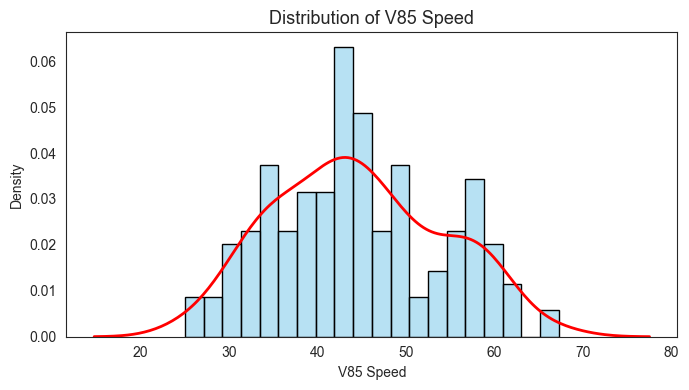

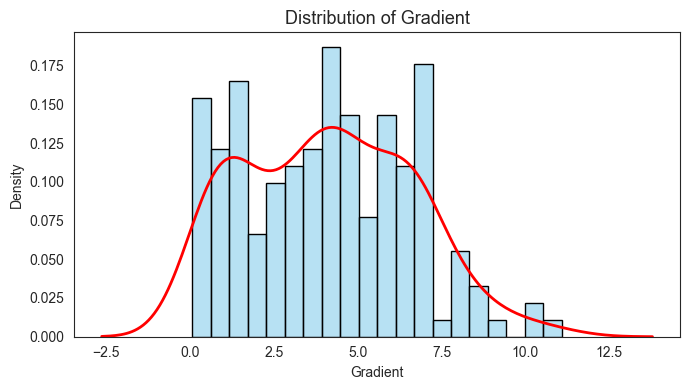

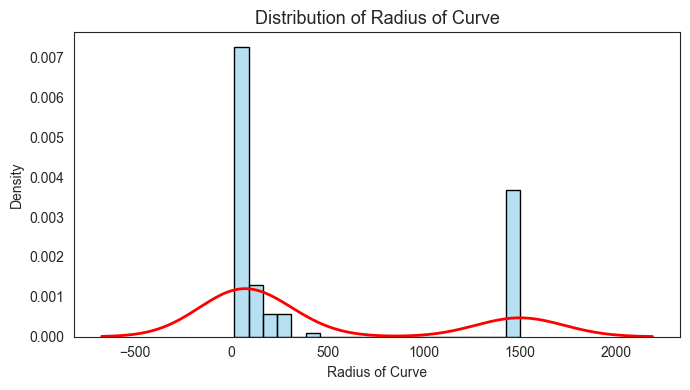

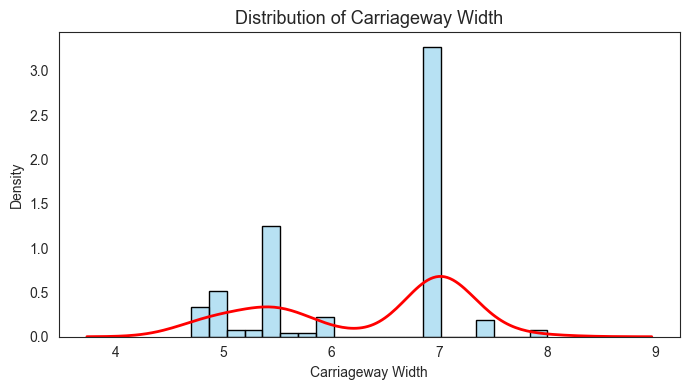

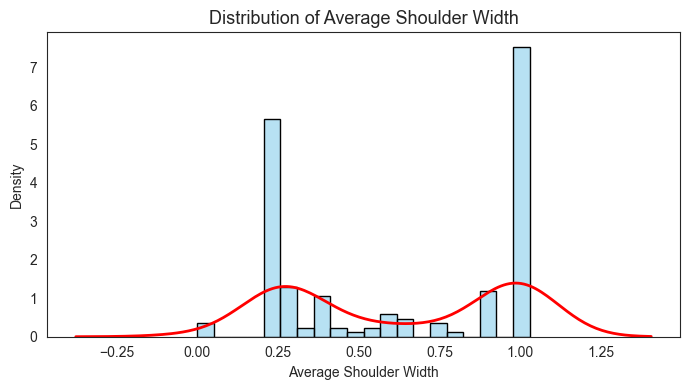

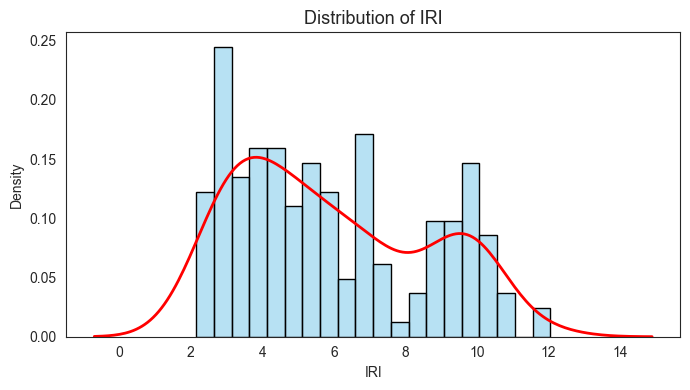

In [15]:
# Select numerical variables
num_cols = [
    "V85 Speed",
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

sns.set_style("white")

for col in num_cols:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        df_encoded[col],
        bins=20,
        stat="density",
        color="skyblue",
        edgecolor="black",
        alpha=0.6
    )

    sns.kdeplot(
        df_encoded[col],
        color="red",
        linewidth=2
    )

    plt.title(f"Distribution of {col}", fontsize=13)
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

Box Plots

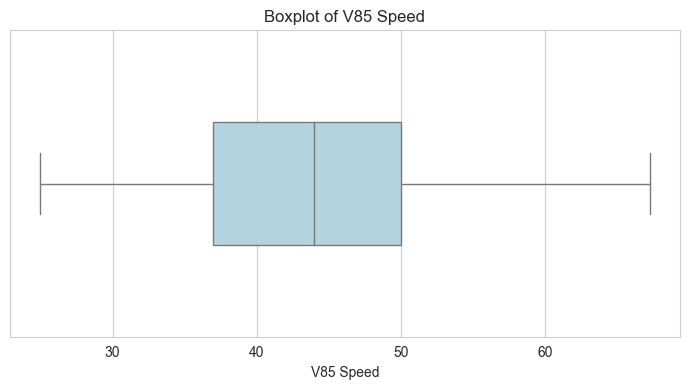

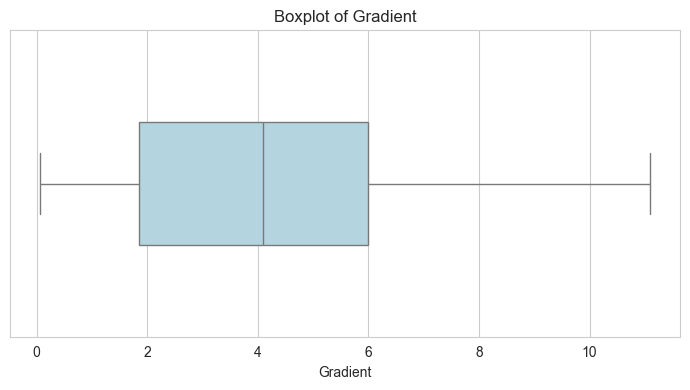

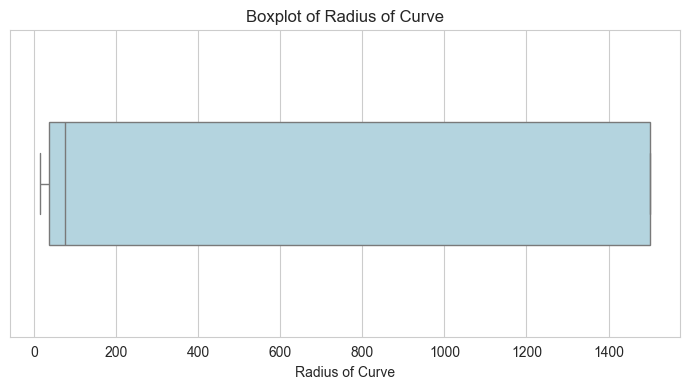

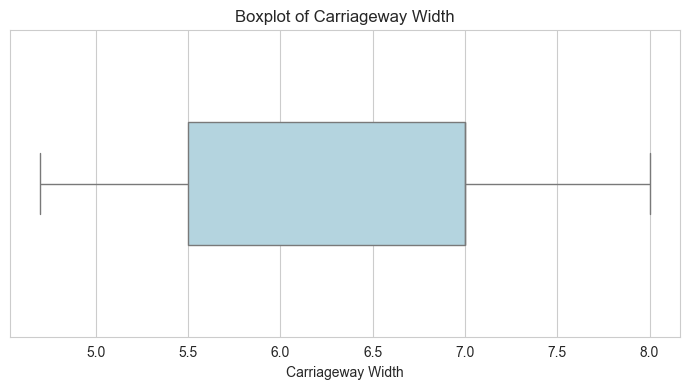

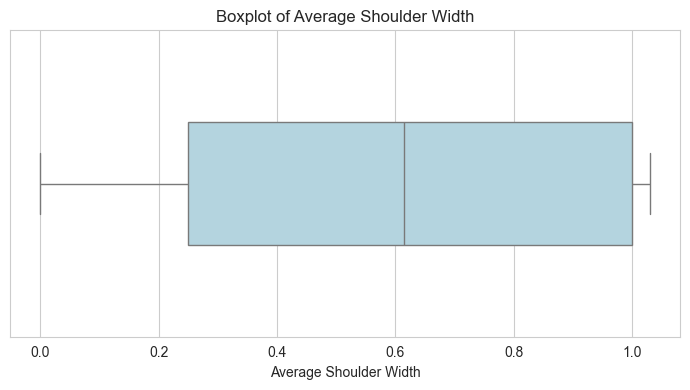

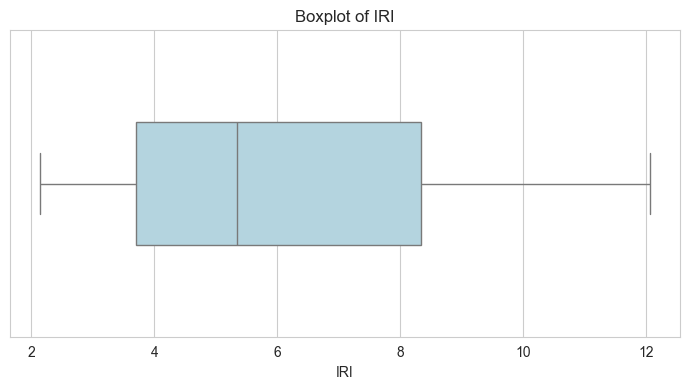

In [16]:
# Select numerical variables
num_cols = [
    "V85 Speed",
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Set plot style
sns.set_style("whitegrid")

# Generate boxplots
for col in num_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x=df_encoded[col],
        color="lightblue",
        width=0.4
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

Skewness

In [17]:
# Calculate skewness

skew_table = pd.DataFrame({
    "Variable": num_cols,
    "Skewness": df_encoded[num_cols].skew().values
})

# Display results
display(skew_table.round(3))

,Variable,Skewness
0,V85 Speed,0.201
1,Gradient,0.234
2,Radius of Curve,0.997
3,Carriageway Width,-0.448
4,Average Shoulder Width,-0.051
5,IRI,0.440


Correlation Matrix

In [18]:
# Select final numerical variables
num_cols = [
    "V85 Speed",
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Calculate correlation matrix
corr_matrix = df_encoded[num_cols].corr(method="pearson")

# Display correlation matrix
display(corr_matrix.round(3))

,V85 Speed,Gradient,Radius of Curve,Carriageway Width,Average Shoulder Width,IRI
V85 Speed,1.000,-0.166,0.601,0.139,-0.185,0.314
Gradient,-0.166,1.000,-0.180,-0.153,-0.025,-0.133
Radius of Curve,0.601,-0.180,1.000,0.026,-0.087,0.182
Carriageway Width,0.139,-0.153,0.026,1.000,-0.058,0.307
Average Shoulder Width,-0.185,-0.025,-0.087,-0.058,1.000,-0.577
IRI,0.314,-0.133,0.182,0.307,-0.577,1.000


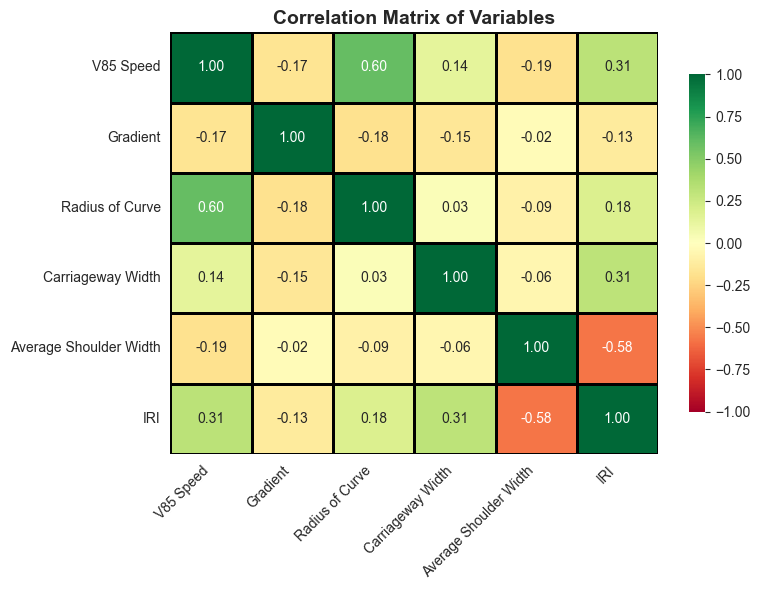

In [19]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdYlGn",
    vmin=-1, vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.8,
    linecolor="black",
    cbar_kws={"shrink": 0.8}
)

plt.title(
    "Correlation Matrix of Variables",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [20]:
# Correlation of independent variables with V85 Speed

speed_corr = corr_matrix["V85 Speed"].drop("V85 Speed")

# Sort correlations
speed_corr = speed_corr.sort_values(ascending=False)

# Display results
display(speed_corr.round(3))

Radius of Curve           0.601
IRI                       0.314
Carriageway Width         0.139
Gradient                 -0.166
Average Shoulder Width   -0.185
Name: V85 Speed, dtype: float64

Relationship Plots

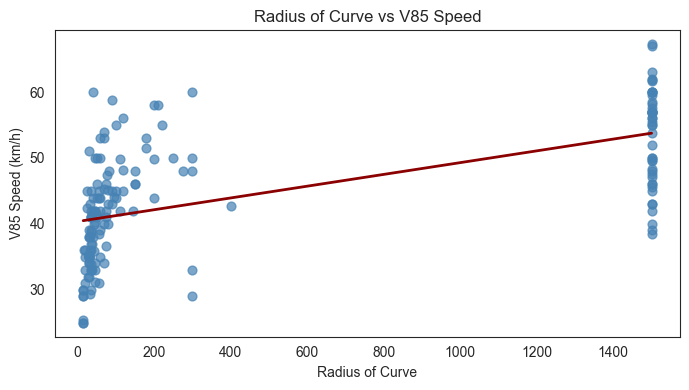

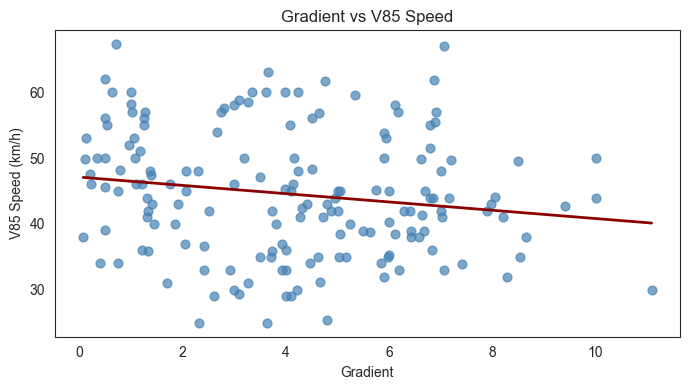

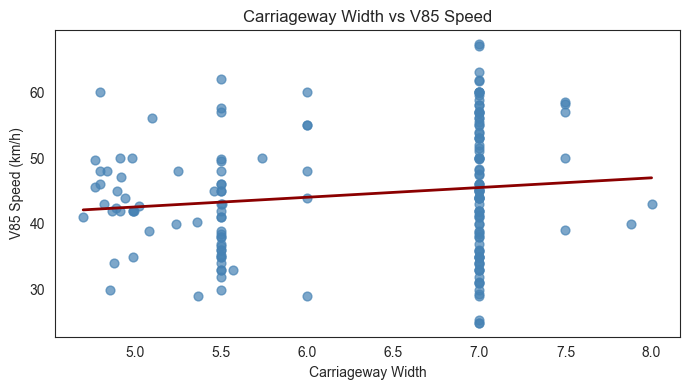

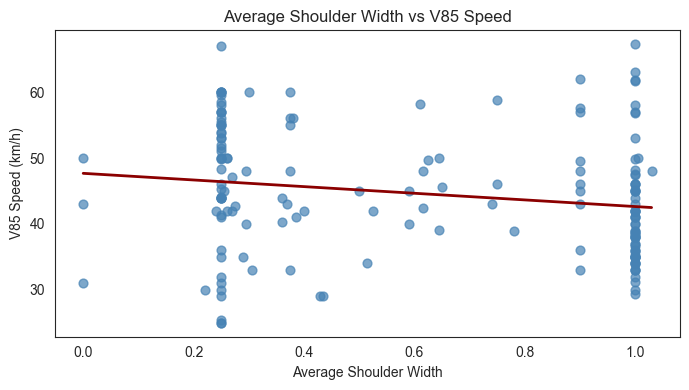

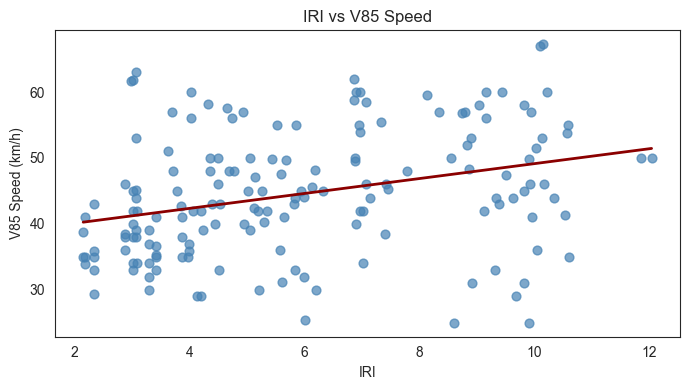

In [21]:
# Final selected independent variables

predictor_cols = [
    "Radius of Curve",
    "Gradient",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

# Set plot style
sns.set_style("white")

# Generate scatter plots with regression lines
for col in predictor_cols:
    plt.figure(figsize=(7, 4))

    sns.regplot(
        x=df_encoded[col],
        y=df_encoded["V85 Speed"],
        scatter_kws={
            "s": 40,
            "color": "steelblue",
            "alpha": 0.7
        },
        line_kws={
            "color": "darkred",
            "linewidth": 2
        },
        ci=None
    )

    plt.title(f"{col} vs V85 Speed")
    plt.xlabel(col)
    plt.ylabel("V85 Speed (km/h)")

    plt.tight_layout()
    plt.show()

Additional Analysis: Radius of Curve vs V85 Speed (Curved Sections Only)

Number of curved sections: 120


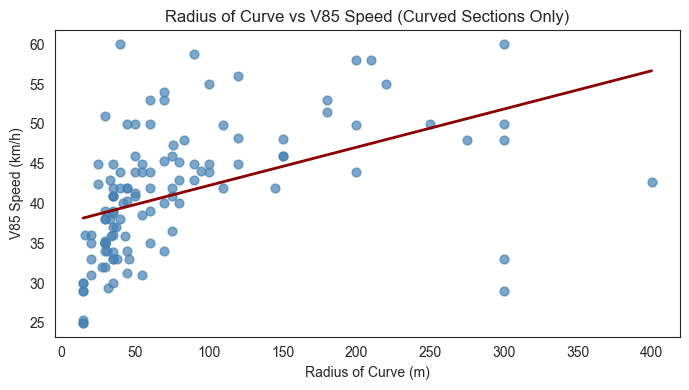

In [22]:
# Select curved sections only (exclude tangent sections)

df_curves = df_encoded[
    df_encoded["Radius of Curve"] != 1500
].copy()

# Display number of curved sections
print("Number of curved sections:", len(df_curves))

# Scatter plot with regression line
sns.set_style("white")

plt.figure(figsize=(7, 4))

sns.regplot(
    x=df_curves["Radius of Curve"],
    y=df_curves["V85 Speed"],
    scatter_kws={
        "s": 40,
        "color": "steelblue",
        "alpha": 0.7
    },
    line_kws={
        "color": "darkred",
        "linewidth": 2
    },
    ci=None
)

plt.title("Radius of Curve vs V85 Speed (Curved Sections Only)")
plt.xlabel("Radius of Curve (m)")
plt.ylabel("V85 Speed (km/h)")

plt.tight_layout()
plt.show()

Calculate Pearson Correlation for Curved Sections Only

In [23]:
# Calculate correlation for curved sections

curve_corr = df_curves[
    ["Radius of Curve", "V85 Speed"]
].corr(method="pearson")

display(curve_corr.round(3))

,Radius of Curve,V85 Speed
Radius of Curve,1.000,0.462
V85 Speed,0.462,1.000


Compare Correlation: All Sections vs Curved Sections

In [24]:
# Correlation including tangent sections
corr_all = df_encoded[
    ["Radius of Curve", "V85 Speed"]
].corr().iloc[0, 1]

# Correlation excluding tangent sections
corr_curves = df_curves[
    ["Radius of Curve", "V85 Speed"]
].corr().iloc[0, 1]

# Comparison table
correlation_comparison = pd.DataFrame({
    "Road Section": [
        "All Sections",
        "Curved Sections Only"
    ],
    "Pearson Correlation": [
        corr_all,
        corr_curves
    ]
})

display(correlation_comparison.round(3))

,Road Section,Pearson Correlation
0,All Sections,0.601
1,Curved Sections Only,0.462


MODEL DEVELOPMENT

Train Test Split

In [25]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (132, 5)
X_test shape : (33, 5)
y_train shape: (132,)
y_test shape : (33,)


Feature Scaling (Standardization)

In [26]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit scaler on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Check scaled data
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (132, 5)
X_test_scaled shape : (33, 5)


MODELING

MLR Model

Training of MLR Model

In [27]:
# Multiple Linear Regression (MLR)

from sklearn.linear_model import LinearRegression

# Initialize MLR model
mlr = LinearRegression()

# Train MLR using unscaled training data
mlr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Predictions using MLR

In [28]:
# Predictions for training and testing data

y_train_pred_mlr = mlr.predict(X_train)
y_test_pred_mlr = mlr.predict(X_test)

Model Evaluation Metrices

In [29]:
# MLR Model Evaluation

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# R² Score
mlr_train_r2 = r2_score(y_train, y_train_pred_mlr)
mlr_test_r2 = r2_score(y_test, y_test_pred_mlr)

# Root Mean Squared Error (RMSE)
mlr_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_mlr))
mlr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_mlr))

# Mean Absolute Error (MAE)
mlr_train_mae = mean_absolute_error(y_train, y_train_pred_mlr)
mlr_test_mae = mean_absolute_error(y_test, y_test_pred_mlr)

# Results Table
mlr_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [mlr_train_r2, mlr_train_rmse, mlr_train_mae],
    "Testing": [mlr_test_r2, mlr_test_rmse, mlr_test_mae]
})

# Display results
display(mlr_results.round(4))

,Metric,Training,Testing
0,R2,0.4238,0.2457
1,RMSE,7.4355,6.6042
2,MAE,5.8476,5.4931


Table of Coefficients of Variables

In [30]:
# MLR Coefficients

coef_table_mlr = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": mlr.coef_
})

# Add intercept as first row
intercept_row = pd.DataFrame({
    "Variable": ["Constant"],
    "Coefficient": [mlr.intercept_]
})

# Combine intercept and coefficients
coef_table_mlr = pd.concat(
    [intercept_row, coef_table_mlr],
    ignore_index=True
)

# Round coefficients
coef_table_mlr["Coefficient"] = coef_table_mlr["Coefficient"].round(4)

# Display results
display(coef_table_mlr)

,Variable,Coefficient
0,Constant,32.9665
1,Gradient,-0.0674
2,Radius of Curve,0.0087
3,Carriageway Width,1.0185
4,Average Shoulder Width,-1.7540
5,IRI,0.4209


In [31]:
# MLR Coefficients

coef_table_mlr = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": mlr.coef_
})

# Add intercept
intercept_row = pd.DataFrame({
    "Variable": ["Constant"],
    "Coefficient": [mlr.intercept_]
})

coef_table_mlr = pd.concat(
    [intercept_row, coef_table_mlr],
    ignore_index=True
)

coef_table_mlr["Coefficient"] = coef_table_mlr["Coefficient"].round(4)

display(coef_table_mlr)


# Generate MLR Prediction Equation

equation = f"V85 Speed = {mlr.intercept_:.4f}"

for variable, coef in zip(X.columns, mlr.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f}({variable})"

print("\nMLR Prediction Equation:")
print(equation)

,Variable,Coefficient
0,Constant,32.9665
1,Gradient,-0.0674
2,Radius of Curve,0.0087
3,Carriageway Width,1.0185
4,Average Shoulder Width,-1.7540
5,IRI,0.4209



MLR Prediction Equation:
V85 Speed = 32.9665 - 0.0674(Gradient) + 0.0087(Radius of Curve) + 1.0185(Carriageway Width) - 1.7540(Average Shoulder Width) + 0.4209(IRI)


Actual vs Predicted Plot

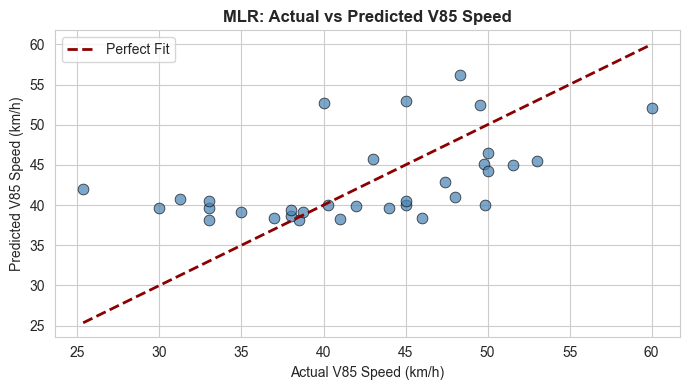

In [32]:
# MLR: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_mlr,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_mlr.min())
max_val = max(y_test.max(), y_test_pred_mlr.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "MLR: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

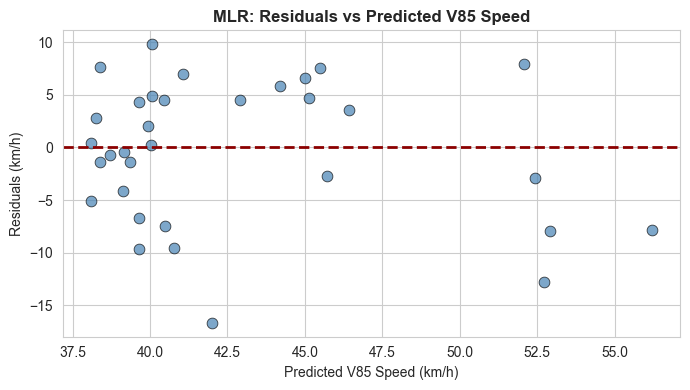

In [33]:
# MLR Residual Analysis

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# Calculate residuals
mlr_residuals = y_test - y_test_pred_mlr

plt.figure(figsize=(7, 4))

# Scatter plot of residuals
sns.scatterplot(
    x=y_test_pred_mlr,
    y=mlr_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero residual
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "MLR: Residuals vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [34]:
# Final MLR Performance Summary

mlr_final = pd.DataFrame({
    "Model": ["MLR"],
    "R2": [round(mlr_test_r2, 3)],
    "RMSE": [round(mlr_test_rmse, 3)],
    "MAE": [round(mlr_test_mae, 3)]
})

# Display results
display(mlr_final)

,Model,R2,RMSE,MAE
0,MLR,0.246,6.604,5.493


RANDOM FOREST MODEL

Random Forest Model Training

In [35]:
# Random Forest Regression (RF)

from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest model
rf = RandomForestRegressor(
    random_state=42
)

# Train RF using unscaled training data
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

Predictions Using Random Forest Model


In [36]:
# Random Forest Predictions

y_train_pred_rf = rf.predict(X_train)
y_test_pred_rf = rf.predict(X_test)

Model Evaluation Metrices


In [37]:
# Random Forest Model Evaluation

# R² Score
rf_train_r2 = r2_score(y_train, y_train_pred_rf)
rf_test_r2 = r2_score(y_test, y_test_pred_rf)

# Root Mean Squared Error (RMSE)
rf_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
rf_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))

# Mean Absolute Error (MAE)
rf_train_mae = mean_absolute_error(y_train, y_train_pred_rf)
rf_test_mae = mean_absolute_error(y_test, y_test_pred_rf)

# Results Table
rf_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [rf_train_r2, rf_train_rmse, rf_train_mae],
    "Testing": [rf_test_r2, rf_test_rmse, rf_test_mae]
})

# Display results
display(rf_results.round(4))

,Metric,Training,Testing
0,R2,0.9263,0.5103
1,RMSE,2.6583,5.3216
2,MAE,2.0257,4.2005


Feature Importance Plot and Table


In [38]:
# Random Forest Feature Importance

rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Display feature importance table
display(rf_importance.round(4))

,Feature,Importance
1,Radius of Curve,0.6119
0,Gradient,0.1573
4,IRI,0.1149
2,Carriageway Width,0.0587
3,Average Shoulder Width,0.0571


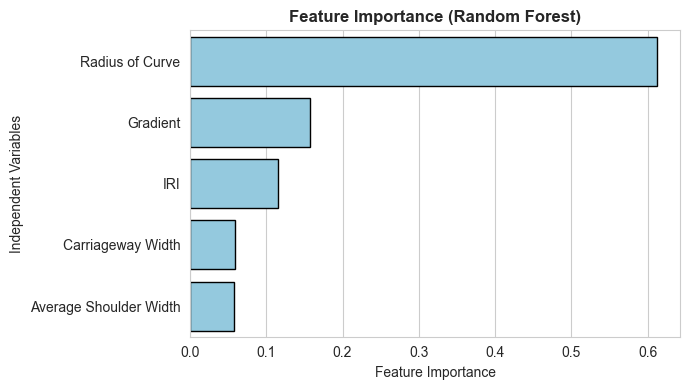

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.barplot(
    x="Importance",
    y="Feature",
    data=rf_importance,
    color="skyblue",
    edgecolor="black"
)

plt.title(
    "Feature Importance (Random Forest)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Independent Variables")

plt.tight_layout()
plt.show()

Actual vs Predicted Plot

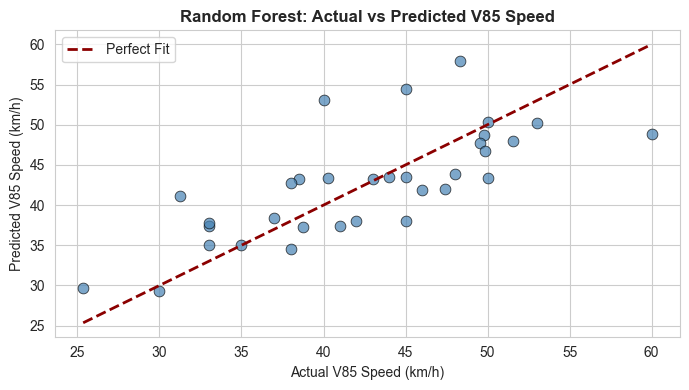

In [40]:
# Random Forest: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_rf,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_rf.min())
max_val = max(y_test.max(), y_test_pred_rf.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Random Forest: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

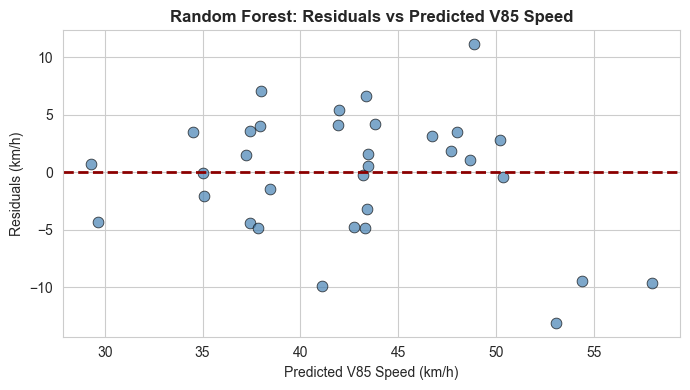

In [41]:
# Random Forest Residual Analysis

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# Calculate residuals
rf_residuals = y_test - y_test_pred_rf

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_rf,
    y=rf_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Random Forest: Residuals vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [42]:
# Final Random Forest Performance Summary

rf_final = pd.DataFrame({
    "Model": ["Random Forest"],
    "R2": [round(rf_test_r2, 3)],
    "RMSE": [round(rf_test_rmse, 3)],
    "MAE": [round(rf_test_mae, 3)]
})

# Display results
display(rf_final)

,Model,R2,RMSE,MAE
0,Random Forest,0.51,5.322,4.201


Hyperparameter Tuned Random Forest Model


Hyperparameter Grid for Random Forest

In [43]:
# Hyperparameter Grid for Random Forest

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

Grid Search Setup and Training

In [44]:
# Random Forest Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using unscaled training data
grid_rf.fit(X_train, y_train)

print("Tuning completed")
print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", round(grid_rf.best_score_, 3))

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Tuning completed
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
Best CV Score: 0.448


Extracting Best Tuned Random Forest Model


In [45]:
# Extract Best Tuned Random Forest Model

best_rf = grid_rf.best_estimator_

best_rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsa

Predictions Using Tuned Random Forest Model


In [46]:
# Predictions Using Tuned Random Forest Model

y_train_pred_rf_tuned = best_rf.predict(X_train)
y_test_pred_rf_tuned = best_rf.predict(X_test)

Model Evaluation Metrices


In [47]:
# Tuned Random Forest Model Evaluation

# R² Score
rf_tuned_train_r2 = r2_score(y_train, y_train_pred_rf_tuned)
rf_tuned_test_r2 = r2_score(y_test, y_test_pred_rf_tuned)

# Root Mean Squared Error (RMSE)
rf_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_rf_tuned))
rf_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_rf_tuned))

# Mean Absolute Error (MAE)
rf_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_rf_tuned)
rf_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_rf_tuned)

# Results Table
rf_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        rf_tuned_train_r2,
        rf_tuned_train_rmse,
        rf_tuned_train_mae
    ],
    "Testing": [
        rf_tuned_test_r2,
        rf_tuned_test_rmse,
        rf_tuned_test_mae
    ]
})

# Display Results
display(rf_tuned_results.round(4))

,Metric,Training,Testing
0,R2,0.7358,0.5968
1,RMSE,5.0344,4.8285
2,MAE,3.9157,3.7643


Feature Importance Table and PLot


In [48]:
# Feature Importance of Tuned Random Forest

rf_tuned_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Display results
display(rf_tuned_importance.round(4))

,Feature,Importance
1,Radius of Curve,0.5977
4,IRI,0.1522
0,Gradient,0.1437
2,Carriageway Width,0.0547
3,Average Shoulder Width,0.0517


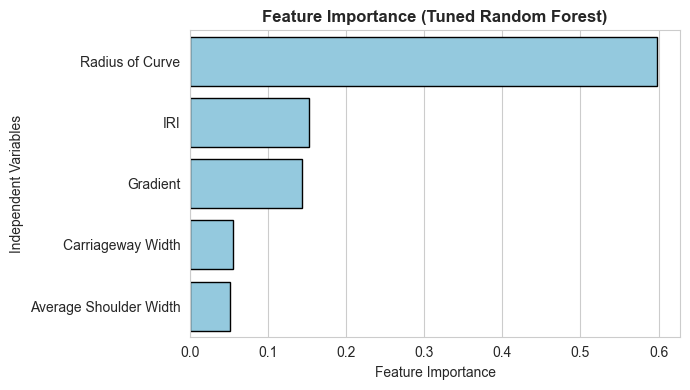

In [49]:
# Feature Importance Plot (Tuned Random Forest)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.barplot(
    x="Importance",
    y="Feature",
    data=rf_tuned_importance,
    color="skyblue",
    edgecolor="black"
)

plt.title(
    "Feature Importance (Tuned Random Forest)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Independent Variables")

plt.tight_layout()
plt.show()

Actual vs Predicted Plot

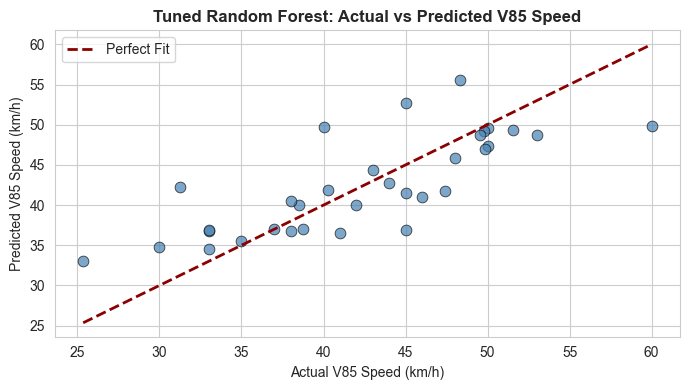

In [50]:
# Tuned Random Forest: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_rf_tuned,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_rf_tuned.min())
max_val = max(y_test.max(), y_test_pred_rf_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Tuned Random Forest: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

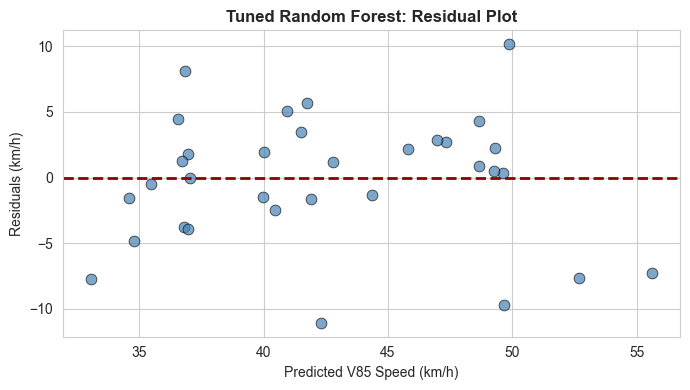

In [51]:
# Tuned Random Forest Residual Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
rf_tuned_residuals = y_test - y_test_pred_rf_tuned

# Set plot style
sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_rf_tuned,
    y=rf_tuned_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Tuned Random Forest: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [52]:
# Final Tuned Random Forest Performance Summary

rf_tuned_final = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "R2": [round(rf_tuned_test_r2, 3)],
    "RMSE": [round(rf_tuned_test_rmse, 3)],
    "MAE": [round(rf_tuned_test_mae, 3)]
})

# Display results
display(rf_tuned_final)

,Model,R2,RMSE,MAE
0,Tuned Random Forest,0.597,4.829,3.764


Base vs Tuned Comparison Table


In [53]:
# Comparison of Baseline and Tuned Random Forest

rf_comparison = pd.concat(
    [rf_final, rf_tuned_final],
    ignore_index=True
)

# Display comparison table
display(rf_comparison)

,Model,R2,RMSE,MAE
0,Random Forest,0.510,5.322,4.201
1,Tuned Random Forest,0.597,4.829,3.764


Best Hyperparameters Table

In [54]:
# Best Hyperparameters of Tuned Random Forest

best_rf_params = pd.DataFrame(
    list(grid_rf.best_params_.items()),
    columns=["Parameter", "Best Value"]
)

# Display results
display(best_rf_params)

,Parameter,Best Value
0,max_depth,None
1,max_features,sqrt
2,min_samples_leaf,2
3,min_samples_split,10
4,n_estimators,100


XGBOOST MODEL

Model Training

In [55]:
# XGBoost Regression Model

from xgboost import XGBRegressor

# Initialize XGBoost model
xgb = XGBRegressor(
    random_state=42,
    objective="reg:squarederror"
)

# Train XGBoost using unscaled training data
xgb.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

Model Predictions

In [56]:
# XGBoost Predictions

y_train_pred_xgb = xgb.predict(X_train)
y_test_pred_xgb = xgb.predict(X_test)

Model Evaluation Metrices

In [57]:
# XGBoost Model Evaluation

# R² Score
xgb_train_r2 = r2_score(y_train, y_train_pred_xgb)
xgb_test_r2 = r2_score(y_test, y_test_pred_xgb)

# Root Mean Squared Error (RMSE)
xgb_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_xgb))
xgb_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_xgb))

# Mean Absolute Error (MAE)
xgb_train_mae = mean_absolute_error(y_train, y_train_pred_xgb)
xgb_test_mae = mean_absolute_error(y_test, y_test_pred_xgb)

# Results Table
xgb_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        xgb_train_r2,
        xgb_train_rmse,
        xgb_train_mae
    ],
    "Testing": [
        xgb_test_r2,
        xgb_test_rmse,
        xgb_test_mae
    ]
})

# Display Results
display(xgb_results.round(4))

,Metric,Training,Testing
0,R2,1.0000,0.3866
1,RMSE,0.0089,5.9557
2,MAE,0.0063,4.7715


Feature Importance Table and Plot

In [58]:
# XGBoost Feature Importance

xgb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Display feature importance table
display(xgb_importance.round(4))

,Feature,Importance
1,Radius of Curve,0.6076
2,Carriageway Width,0.1880
3,Average Shoulder Width,0.1027
0,Gradient,0.0514
4,IRI,0.0503


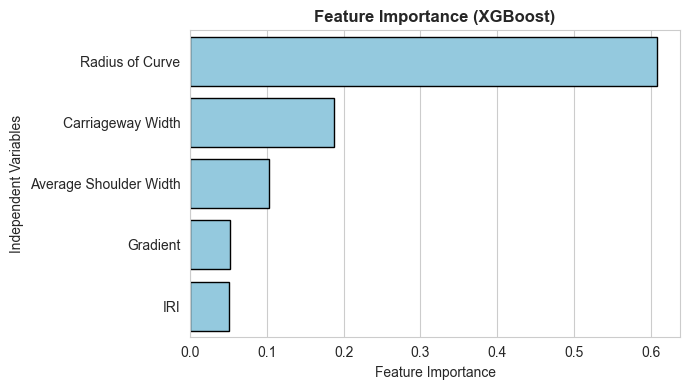

In [59]:
# XGBoost Feature Importance Plot

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.barplot(
    x="Importance",
    y="Feature",
    data=xgb_importance,
    color="skyblue",
    edgecolor="black"
)

plt.title(
    "Feature Importance (XGBoost)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Independent Variables")

plt.tight_layout()
plt.show()

Actual vs Predicted Plot

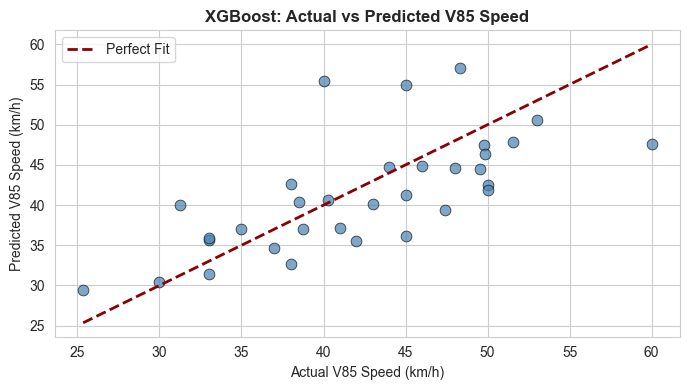

In [60]:
# XGBoost: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_xgb,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_xgb.min())
max_val = max(y_test.max(), y_test_pred_xgb.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "XGBoost: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual PLot

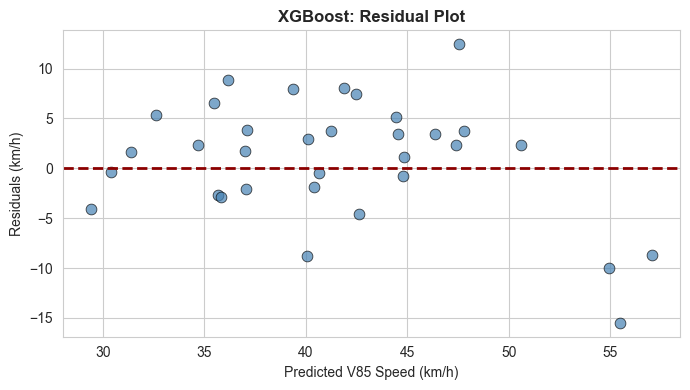

In [61]:
# XGBoost Residual Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
xgb_residuals = y_test - y_test_pred_xgb

# Set plot style
sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_xgb,
    y=xgb_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "XGBoost: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [62]:
# Final XGBoost Performance Summary

xgb_final = pd.DataFrame({
    "Model": ["XGBoost"],
    "R2": [round(xgb_test_r2, 3)],
    "RMSE": [round(xgb_test_rmse, 3)],
    "MAE": [round(xgb_test_mae, 3)]
})

# Display results
display(xgb_final)

,Model,R2,RMSE,MAE
0,XGBoost,0.387,5.956,4.772


Hyperparameter Tuned XGBoost Model


Hyperparameter Grid Definition


In [63]:
# Hyperparameter Grid for XGBoost

param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

Grid Search Setup and Training

In [64]:
# XGBoost Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

grid_xgb = GridSearchCV(
    estimator=XGBRegressor(
        random_state=42,
        objective="reg:squarederror",
        n_jobs=1
    ),
    param_grid=param_grid_xgb,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using unscaled training data
grid_xgb.fit(X_train, y_train)

print("Tuning completed")
print("Best Parameters:", grid_xgb.best_params_)
print("Best CV Score:", round(grid_xgb.best_score_, 3))

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Tuning completed
Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}
Best CV Score: 0.449


Best Model Extraction

In [65]:
# Extract Best Tuned XGBoost Model

best_xgb = grid_xgb.best_estimator_

best_xgb

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

Predictions Using Tuned Model


In [66]:
# Predictions Using Tuned XGBoost Model

y_train_pred_xgb_tuned = best_xgb.predict(X_train)
y_test_pred_xgb_tuned = best_xgb.predict(X_test)

Model Evaluation Metrices


In [67]:
# Tuned XGBoost Model Evaluation

# R² Score
xgb_tuned_train_r2 = r2_score(y_train, y_train_pred_xgb_tuned)
xgb_tuned_test_r2 = r2_score(y_test, y_test_pred_xgb_tuned)

# Root Mean Squared Error (RMSE)
xgb_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_xgb_tuned))
xgb_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_xgb_tuned))

# Mean Absolute Error (MAE)
xgb_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_xgb_tuned)
xgb_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_xgb_tuned)

# Results Table
xgb_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        xgb_tuned_train_r2,
        xgb_tuned_train_rmse,
        xgb_tuned_train_mae
    ],
    "Testing": [
        xgb_tuned_test_r2,
        xgb_tuned_test_rmse,
        xgb_tuned_test_mae
    ]
})

# Display Results
display(xgb_tuned_results.round(4))

,Metric,Training,Testing
0,R2,0.7062,0.5453
1,RMSE,5.3089,5.1275
2,MAE,4.1120,4.1258


Feature Importance Table and Plot


In [68]:
# Feature Importance of Tuned XGBoost

xgb_tuned_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_xgb.feature_importances_
})

# Sort from highest to lowest importance
xgb_tuned_importance = xgb_tuned_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Round values for presentation
xgb_tuned_importance["Importance"] = (
    xgb_tuned_importance["Importance"].round(4)
)

# Display results
display(xgb_tuned_importance)

,Feature,Importance
0,Radius of Curve,0.5522
1,Carriageway Width,0.1241
2,IRI,0.1123
3,Gradient,0.1074
4,Average Shoulder Width,0.1041


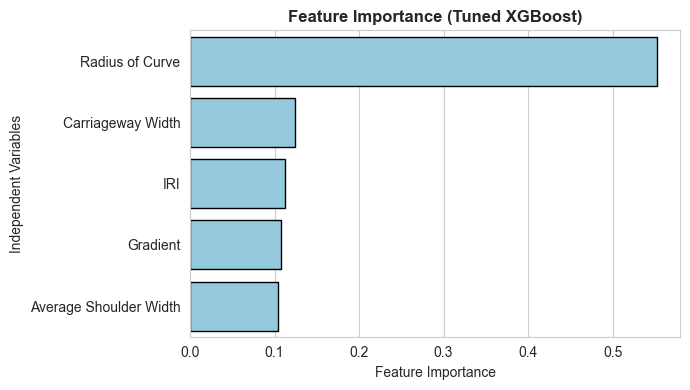

In [69]:
# Tuned XGBoost Feature Importance Plot

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.barplot(
    x="Importance",
    y="Feature",
    data=xgb_tuned_importance,
    color="skyblue",
    edgecolor="black"
)

plt.title(
    "Feature Importance (Tuned XGBoost)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Independent Variables")

plt.tight_layout()
plt.show()

Actual vs Predicted Plot


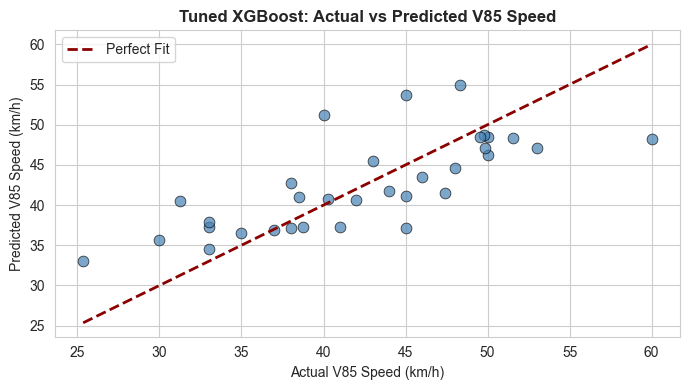

In [70]:
# Tuned XGBoost: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_xgb_tuned,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_xgb_tuned.min())
max_val = max(y_test.max(), y_test_pred_xgb_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Tuned XGBoost: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

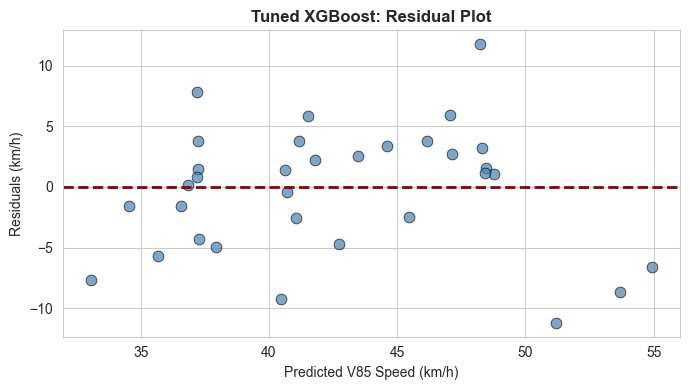

In [71]:
# Tuned XGBoost Residual Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
xgb_tuned_residuals = y_test - y_test_pred_xgb_tuned

# Set plot style
sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_xgb_tuned,
    y=xgb_tuned_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Tuned XGBoost: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [72]:
# Final Tuned XGBoost Performance Summary

xgb_tuned_final = pd.DataFrame({
    "Model": ["Tuned XGBoost"],
    "R2": [round(xgb_tuned_test_r2, 3)],
    "RMSE": [round(xgb_tuned_test_rmse, 3)],
    "MAE": [round(xgb_tuned_test_mae, 3)]
})

# Display results
display(xgb_tuned_final)

,Model,R2,RMSE,MAE
0,Tuned XGBoost,0.545,5.127,4.126


Base vs Tuned Model Comparison


In [73]:
# Comparison of Baseline and Tuned XGBoost

xgb_comparison = pd.concat(
    [xgb_final, xgb_tuned_final],
    ignore_index=True
)

# Display comparison table
display(xgb_comparison)

,Model,R2,RMSE,MAE
0,XGBoost,0.387,5.956,4.772
1,Tuned XGBoost,0.545,5.127,4.126


Best Hyperparameters Table


In [74]:
# Best Hyperparameters of Tuned XGBoost

best_xgb_params = pd.DataFrame(
    list(grid_xgb.best_params_.items()),
    columns=["Parameter", "Best Value"]
)

# Display results
display(best_xgb_params)

,Parameter,Best Value
0,colsample_bytree,1.00
1,learning_rate,0.01
2,max_depth,3.00
3,n_estimators,200.00
4,subsample,0.70


SUPPORT VECTOR REGRESSION MODEL (SVR)

Model Training

In [75]:
# Support Vector Regression (SVR)

from sklearn.svm import SVR

# Initialize SVR model
svr = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

# Train SVR using scaled training data
svr.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


Model Prediction

In [76]:
# SVR Model Predictions

y_train_pred_svr = svr.predict(X_train_scaled)
y_test_pred_svr = svr.predict(X_test_scaled)

Model Evaluation Metrices

In [77]:
# SVR Model Evaluation

# R² Score
svr_train_r2 = r2_score(y_train, y_train_pred_svr)
svr_test_r2 = r2_score(y_test, y_test_pred_svr)

# Root Mean Squared Error (RMSE)
svr_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_svr))
svr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_svr))

# Mean Absolute Error (MAE)
svr_train_mae = mean_absolute_error(y_train, y_train_pred_svr)
svr_test_mae = mean_absolute_error(y_test, y_test_pred_svr)

# Results Table
svr_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        svr_train_r2,
        svr_train_rmse,
        svr_train_mae
    ],
    "Testing": [
        svr_test_r2,
        svr_test_rmse,
        svr_test_mae
    ]
})

# Display Results
display(svr_results.round(4))

,Metric,Training,Testing
0,R2,0.6571,-0.0675
1,RMSE,5.7359,7.8566
2,MAE,3.3379,6.1901


Actual vs Predicted Plot

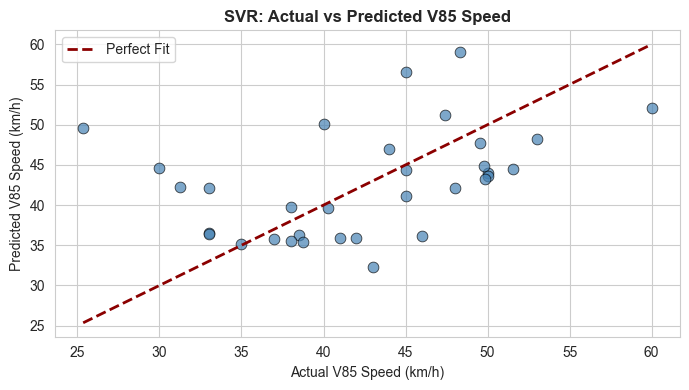

In [78]:
# SVR: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_svr,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_svr.min())
max_val = max(y_test.max(), y_test_pred_svr.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "SVR: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

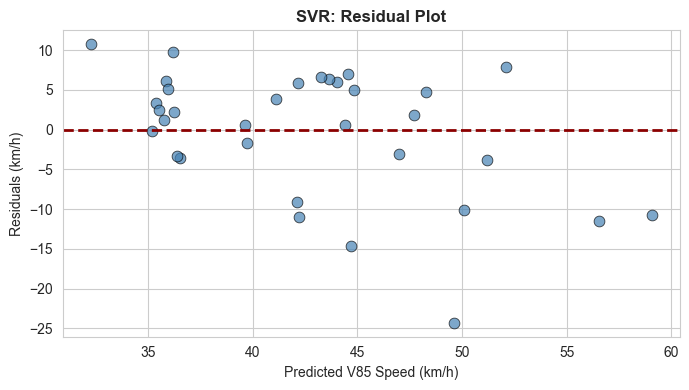

In [79]:
# SVR Residual Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
svr_residuals = y_test - y_test_pred_svr

# Set plot style
sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_svr,
    y=svr_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "SVR: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [80]:
# Final SVR Performance Summary

svr_final = pd.DataFrame({
    "Model": ["SVR"],
    "R2": [round(svr_test_r2, 3)],
    "RMSE": [round(svr_test_rmse, 3)],
    "MAE": [round(svr_test_mae, 3)]
})

# Display results
display(svr_final)

,Model,R2,RMSE,MAE
0,SVR,-0.067,7.857,6.19


Hyperparameter Tuned SVR Model


Hyperparameter Grid Definition


In [81]:
# Hyperparameter Grid for SVR

param_grid_svr = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.01, 0.1, 0.5, 1],
    "svr__gamma": ["scale", 0.01, 0.1, 1],
    "svr__kernel": ["rbf"]
}

Grid Search Setup and Training


In [82]:
# SVR Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Create pipeline
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

# Grid Search
grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using unscaled data (pipeline handles scaling)
grid_svr.fit(X_train, y_train)

print("Tuning completed")
print("Best Parameters:", grid_svr.best_params_)
print("Best CV Score:", round(grid_svr.best_score_, 3))

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Tuning completed
Best Parameters: {'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}
Best CV Score: 0.332


Best Model Extraction


In [83]:
# Best Model Extraction

best_svr = grid_svr.best_estimator_

best_svr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0


Predictions Using Tuned Model


In [84]:
# Predictions Using Tuned SVR Model

y_train_pred_svr_tuned = best_svr.predict(X_train)
y_test_pred_svr_tuned = best_svr.predict(X_test)

Model Evaluation Metrices


In [85]:
# Tuned SVR Model Evaluation

# R² Score
svr_tuned_train_r2 = r2_score(y_train, y_train_pred_svr_tuned)
svr_tuned_test_r2 = r2_score(y_test, y_test_pred_svr_tuned)

# Root Mean Squared Error (RMSE)
svr_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_svr_tuned))
svr_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_svr_tuned))

# Mean Absolute Error (MAE)
svr_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_svr_tuned)
svr_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_svr_tuned)

# Results Table
svr_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        svr_tuned_train_r2,
        svr_tuned_train_rmse,
        svr_tuned_train_mae
    ],
    "Testing": [
        svr_tuned_test_r2,
        svr_tuned_test_rmse,
        svr_tuned_test_mae
    ]
})

# Display Results
display(svr_tuned_results.round(4))

,Metric,Training,Testing
0,R2,0.4496,0.1816
1,RMSE,7.2669,6.8793
2,MAE,5.4137,5.5586


Actual vs Predicted Plot

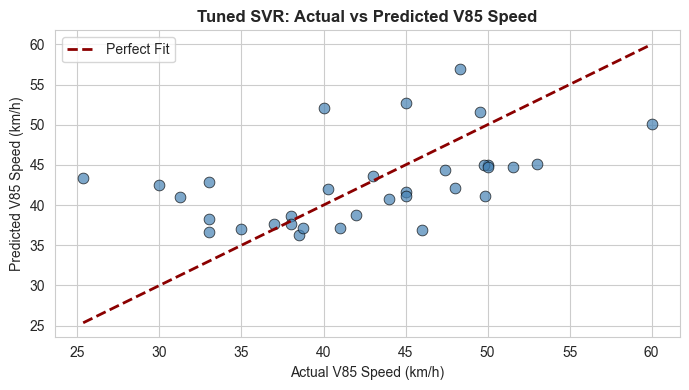

In [86]:
# Tuned SVR: Actual vs Predicted

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.scatterplot(
    x=y_test,
    y=y_test_pred_svr_tuned,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_svr_tuned.min())
max_val = max(y_test.max(), y_test_pred_svr_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Tuned SVR: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

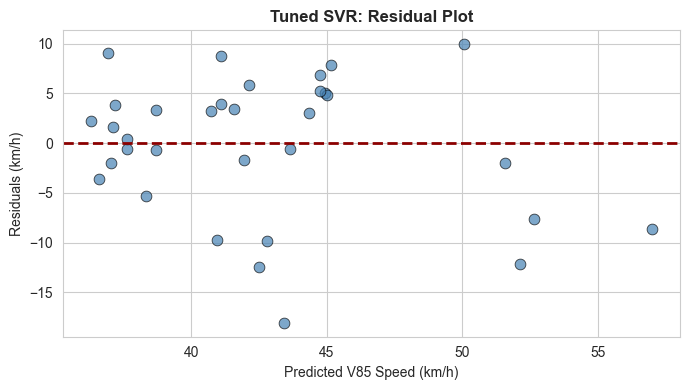

In [87]:
# Tuned SVR Residual Analysis

svr_tuned_residuals = y_test - y_test_pred_svr_tuned

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.scatterplot(
    x=y_test_pred_svr_tuned,
    y=svr_tuned_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Tuned SVR: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [88]:
# Tuned SVR Performance Summary

svr_tuned_final = pd.DataFrame({
    "Model": ["Tuned SVR"],
    "R2": [round(svr_tuned_test_r2, 3)],
    "RMSE": [round(svr_tuned_test_rmse, 3)],
    "MAE": [round(svr_tuned_test_mae, 3)]
})

# Display results
display(svr_tuned_final)

,Model,R2,RMSE,MAE
0,Tuned SVR,0.182,6.879,5.559


Base vs Tuned Comparison Table


In [89]:
# Baseline vs Tuned SVR Comparison

svr_comparison = pd.concat(
    [svr_final, svr_tuned_final],
    ignore_index=True
)

# Display comparison
display(svr_comparison)

,Model,R2,RMSE,MAE
0,SVR,-0.067,7.857,6.190
1,Tuned SVR,0.182,6.879,5.559


Best Hyperparameters Table


In [90]:
# Best Hyperparameters of Tuned SVR

best_svr_params = pd.DataFrame(
    list(grid_svr.best_params_.items()),
    columns=["Parameter", "Best Value"]
)

# Remove pipeline prefix for presentation
best_svr_params["Parameter"] = (
    best_svr_params["Parameter"].str.replace(
        "svr__", "", regex=False
    )
)

# Display results
display(best_svr_params)

,Parameter,Best Value
0,C,100
1,epsilon,0.01
2,gamma,0.01
3,kernel,rbf


Artificial Neural Network (ANN) Model

Model Training


In [91]:
# Artificial Neural Network (ANN)

from sklearn.neural_network import MLPRegressor

# Initialize ANN model
ann = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)

# Train ANN using scaled training data
ann.fit(X_train_scaled, y_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


Model Predictions


In [92]:
# ANN Model Predictions

y_train_pred_ann = ann.predict(X_train_scaled)
y_test_pred_ann = ann.predict(X_test_scaled)

Model Evaluation Metrices


In [93]:
# ANN Model Evaluation

# R² Score
ann_train_r2 = r2_score(y_train, y_train_pred_ann)
ann_test_r2 = r2_score(y_test, y_test_pred_ann)

# Root Mean Squared Error (RMSE)
ann_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_ann))
ann_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_ann))

# Mean Absolute Error (MAE)
ann_train_mae = mean_absolute_error(y_train, y_train_pred_ann)
ann_test_mae = mean_absolute_error(y_test, y_test_pred_ann)

# Results Table
ann_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        ann_train_r2,
        ann_train_rmse,
        ann_train_mae
    ],
    "Testing": [
        ann_test_r2,
        ann_test_rmse,
        ann_test_mae
    ]
})

# Display results
display(ann_results.round(4))

,Metric,Training,Testing
0,R2,0.9109,-0.0879
1,RMSE,2.9237,7.9315
2,MAE,1.9474,6.2032


Actual vs Predicted Plot

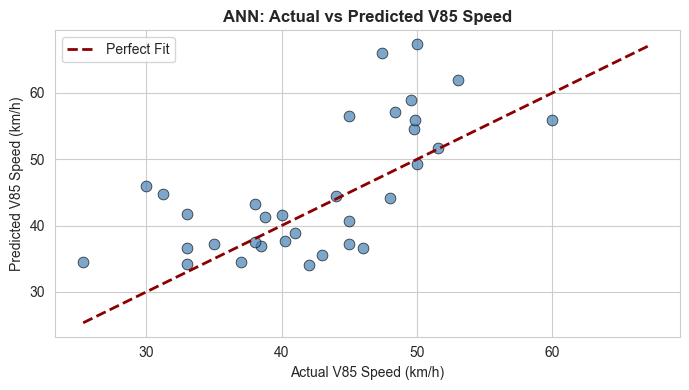

In [94]:
# ANN: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_ann,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_ann.min())
max_val = max(y_test.max(), y_test_pred_ann.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "ANN: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

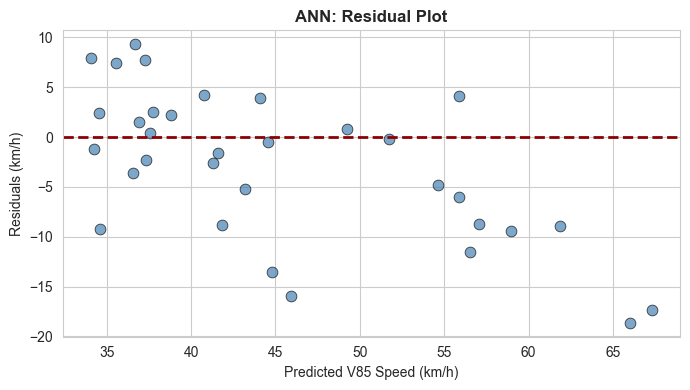

In [95]:
# ANN Residual Analysis

# Calculate residuals
ann_residuals = y_test - y_test_pred_ann

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_ann,
    y=ann_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "ANN: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [96]:
# Final ANN Performance Summary

ann_final = pd.DataFrame({
    "Model": ["ANN"],
    "R2": [round(ann_test_r2, 3)],
    "RMSE": [round(ann_test_rmse, 3)],
    "MAE": [round(ann_test_mae, 3)]
})

# Display results
display(ann_final)

,Model,R2,RMSE,MAE
0,ANN,-0.088,7.931,6.203


Hyperparameter Tuned ANN Model


Hyperparameter Grid Definition


In [97]:
# Hyperparameter Grid for ANN

param_grid_ann = {
    "ann__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "ann__activation": ["relu", "tanh"],
    "ann__alpha": [0.0001, 0.001, 0.01],
    "ann__learning_rate_init": [0.001, 0.01]
}

Grid Search Setup and Training


In [98]:
# ANN Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create pipeline
ann_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPRegressor(
        max_iter=3000,
        random_state=42
    ))
])

# Grid Search
grid_ann = GridSearchCV(
    estimator=ann_pipeline,
    param_grid=param_grid_ann,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train using unscaled data (pipeline handles scaling)
grid_ann.fit(X_train, y_train)

print("Tuning completed")
print("Best Parameters:", grid_ann.best_params_)
print("Best CV Score:", round(grid_ann.best_score_, 3))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Tuning completed
Best Parameters: {'ann__activation': 'tanh', 'ann__alpha': 0.01, 'ann__hidden_layer_sizes': (32,), 'ann__learning_rate_init': 0.001}
Best CV Score: 0.353


Best Model Extraction


In [99]:
# Best Model Extraction

best_ann = grid_ann.best_estimator_

best_ann

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('ann', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(32,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_traini

Prediction Using Tuned Model


In [100]:
# Predictions Using Tuned ANN Model

y_train_pred_ann_tuned = best_ann.predict(X_train)
y_test_pred_ann_tuned = best_ann.predict(X_test)

Model Evaluation Metrices


In [101]:
# Tuned ANN Model Evaluation

# R² Score
ann_tuned_train_r2 = r2_score(y_train, y_train_pred_ann_tuned)
ann_tuned_test_r2 = r2_score(y_test, y_test_pred_ann_tuned)

# Root Mean Squared Error (RMSE)
ann_tuned_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_ann_tuned))
ann_tuned_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_ann_tuned))

# Mean Absolute Error (MAE)
ann_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_ann_tuned)
ann_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_ann_tuned)

# Results Table
ann_tuned_results = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Training": [
        ann_tuned_train_r2,
        ann_tuned_train_rmse,
        ann_tuned_train_mae
    ],
    "Testing": [
        ann_tuned_test_r2,
        ann_tuned_test_rmse,
        ann_tuned_test_mae
    ]
})

# Display Results
display(ann_tuned_results.round(4))

,Metric,Training,Testing
0,R2,0.5020,0.1421
1,RMSE,6.9120,7.0432
2,MAE,5.3194,5.7179


Actual vs Predicted Plot

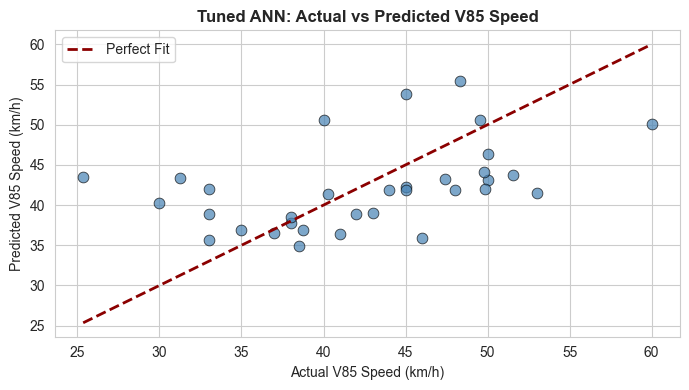

In [102]:
# Tuned ANN: Actual vs Predicted V85 Speed

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test,
    y=y_test_pred_ann_tuned,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Perfect fit line
min_val = min(y_test.min(), y_test_pred_ann_tuned.min())
max_val = max(y_test.max(), y_test_pred_ann_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Perfect Fit"
)

plt.xlabel("Actual V85 Speed (km/h)")
plt.ylabel("Predicted V85 Speed (km/h)")

plt.title(
    "Tuned ANN: Actual vs Predicted V85 Speed",
    fontsize=12,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Plot

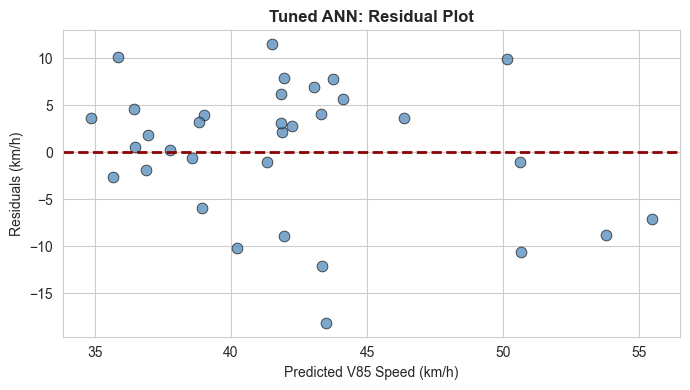

In [103]:
# Tuned ANN Residual Analysis

# Calculate residuals
ann_tuned_residuals = y_test - y_test_pred_ann_tuned

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

# Scatter plot
sns.scatterplot(
    x=y_test_pred_ann_tuned,
    y=ann_tuned_residuals,
    color="steelblue",
    s=60,
    alpha=0.7,
    edgecolor="black"
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="darkred",
    linewidth=2
)

plt.xlabel("Predicted V85 Speed (km/h)")
plt.ylabel("Residuals (km/h)")

plt.title(
    "Tuned ANN: Residual Plot",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Result Table

In [104]:
# Final Tuned ANN Performance Summary

ann_tuned_final = pd.DataFrame({
    "Model": ["Tuned ANN"],
    "R2": [round(ann_tuned_test_r2, 3)],
    "RMSE": [round(ann_tuned_test_rmse, 3)],
    "MAE": [round(ann_tuned_test_mae, 3)]
})

# Display results
display(ann_tuned_final)

,Model,R2,RMSE,MAE
0,Tuned ANN,0.142,7.043,5.718


Base vs Tuned Comparison


In [105]:
# Baseline vs Tuned ANN Comparison

ann_comparison = pd.concat(
    [ann_final, ann_tuned_final],
    ignore_index=True
)

# Display comparison
display(ann_comparison)

,Model,R2,RMSE,MAE
0,ANN,-0.088,7.931,6.203
1,Tuned ANN,0.142,7.043,5.718


Best Hyperparameters Table


In [106]:
# Best Hyperparameters of Tuned ANN

best_ann_params = pd.DataFrame(
    list(grid_ann.best_params_.items()),
    columns=["Parameter", "Best Value"]
)

# Remove pipeline prefix
best_ann_params["Parameter"] = (
    best_ann_params["Parameter"].str.replace(
        "ann__", "", regex=False
    )
)

# Display results
display(best_ann_params)

,Parameter,Best Value
0,activation,tanh
1,alpha,0.01
2,hidden_layer_sizes,"(32,)"
3,learning_rate_init,0.001


Final Comparison of All Models


In [107]:
# Step 1: Assign Model Type (Base or Tuned)

mlr_final["Type"] = "Base"

rf_final["Type"] = "Base"
rf_tuned_final["Type"] = "Tuned"

xgb_final["Type"] = "Base"
xgb_tuned_final["Type"] = "Tuned"

svr_final["Type"] = "Base"
svr_tuned_final["Type"] = "Tuned"

ann_final["Type"] = "Base"
ann_tuned_final["Type"] = "Tuned"


# Step 2: Combine All Nine Models

master_table = pd.concat([
    mlr_final,
    rf_final,
    rf_tuned_final,
    xgb_final,
    xgb_tuned_final,
    svr_final,
    svr_tuned_final,
    ann_final,
    ann_tuned_final
], ignore_index=True)


# Step 3: Arrange Columns

master_table = master_table[
    ["Model", "Type", "R2", "RMSE", "MAE"]
].copy()


# Step 4: Sort by RMSE (Lowest = Best)

master_table = master_table.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)


# Step 5: Add Model Ranking

master_table.insert(
    0,
    "Rank (RMSE)",
    range(1, len(master_table) + 1)
)


# Step 6: Round Results

master_table[["R2", "RMSE", "MAE"]] = (
    master_table[["R2", "RMSE", "MAE"]].round(3)
)


# Step 7: Display Final Comparison Table

display(master_table)

,Rank (RMSE),Model,Type,R2,RMSE,MAE
0,1,Tuned Random Forest,Tuned,0.597,4.829,3.764
1,2,Tuned XGBoost,Tuned,0.545,5.127,4.126
2,3,Random Forest,Base,0.510,5.322,4.201
3,4,XGBoost,Base,0.387,5.956,4.772
4,5,MLR,Base,0.246,6.604,5.493
5,6,Tuned SVR,Tuned,0.182,6.879,5.559
6,7,Tuned ANN,Tuned,0.142,7.043,5.718
7,8,SVR,Base,-0.067,7.857,6.190
8,9,ANN,Base,-0.088,7.931,6.203


In [108]:
# Best Performing Model Based on RMSE

best_model = master_table.iloc[0]

print("Best Model:", best_model["Model"])
print("Testing R²:", best_model["R2"])
print("Testing RMSE:", best_model["RMSE"])
print("Testing MAE:", best_model["MAE"])

Best Model: Tuned Random Forest
Testing R²: 0.597
Testing RMSE: 4.829
Testing MAE: 3.764


BOOTSTRAPPING FOR BEST TWO MODELS

Preparation of Data

In [109]:
# Prepare data for Bootstrap Evaluation

X_boot = X_train.copy()
y_boot = y_train.copy()

print("X_boot shape:", X_boot.shape)
print("y_boot shape:", y_boot.shape)

X_boot shape: (132, 5)
y_boot shape: (132,)


Import Required Libraries

In [110]:
# Import Required Libraries

from sklearn.utils import resample
from sklearn.base import clone

Create Bootstrap OOB Evaluation Function

In [111]:
# Bootstrap OOB Evaluation Function

def bootstrap_oob_evaluation(model, X, y, n_bootstrap=1000, random_state=42):

    r2_list = []
    rmse_list = []
    mae_list = []
    used_iterations = []

    X_array = np.array(X)
    y_array = np.array(y)

    n = len(X_array)
    indices = np.arange(n)

    for i in range(n_bootstrap):

        # Bootstrap sample indices
        boot_idx = resample(
            indices,
            replace=True,
            n_samples=n,
            random_state=random_state + i
        )

        # Out-of-bag indices
        oob_idx = np.setdiff1d(indices, boot_idx)

        # Skip if insufficient OOB observations
        if len(oob_idx) < 2:
            continue

        X_train_boot = X_array[boot_idx]
        y_train_boot = y_array[boot_idx]

        X_test_oob = X_array[oob_idx]
        y_test_oob = y_array[oob_idx]

        # Clone model
        model_i = clone(model)

        # Train on bootstrap sample
        model_i.fit(X_train_boot, y_train_boot)

        # Predict OOB observations
        y_pred_oob = model_i.predict(X_test_oob)

        # Calculate metrics
        r2 = r2_score(y_test_oob, y_pred_oob)
        rmse = np.sqrt(mean_squared_error(y_test_oob, y_pred_oob))
        mae = mean_absolute_error(y_test_oob, y_pred_oob)

        r2_list.append(r2)
        rmse_list.append(rmse)
        mae_list.append(mae)
        used_iterations.append(i + 1)

    results = pd.DataFrame({
        "Iteration": used_iterations,
        "R2": r2_list,
        "RMSE": rmse_list,
        "MAE": mae_list
    })

    return results

Bootstrap Evaluation for Tuned Random Forest

In [112]:
# Bootstrap for Tuned Random Forest

rf_boot_results = bootstrap_oob_evaluation(
    model=best_rf,
    X=X_boot,
    y=y_boot,
    n_bootstrap=1000,
    random_state=42
)

# Display results
display(rf_boot_results.head())

,Iteration,R2,RMSE,MAE
0,1,0.316884,8.281960,6.133892
1,2,0.291151,7.448467,5.806550
2,3,0.299946,8.290198,6.554013
3,4,0.496386,6.203564,5.145780
4,5,0.425146,7.618340,5.689186


Bootstrap OOB Evaluation for Tuned XGBoost

In [113]:
# Bootstrap OOB Evaluation for Tuned XGBoost

xgb_boot_results = bootstrap_oob_evaluation(
    model=best_xgb,
    X=X_boot,
    y=y_boot,
    n_bootstrap=1000,
    random_state=42
)

# Display first five results
display(xgb_boot_results.head())

,Iteration,R2,RMSE,MAE
0,1,0.291514,8.434348,6.307513
1,2,0.258019,7.620547,6.035131
2,3,0.395764,7.701979,5.698651
3,4,0.515850,6.082501,4.878391
4,5,0.440380,7.516719,5.530174


Summary Statistics

In [114]:
# Function to Summarize Bootstrap Results

def summarize_bootstrap_results(results, model_name):

    summary = pd.DataFrame({
        "Model": [model_name],
        "Mean R2": [results["R2"].mean()],
        "Std R2": [results["R2"].std()],
        "Mean RMSE": [results["RMSE"].mean()],
        "Std RMSE": [results["RMSE"].std()],
        "Mean MAE": [results["MAE"].mean()],
        "Std MAE": [results["MAE"].std()]
    })

    return summary.round(3)

In [115]:
# Bootstrap Summary for Tuned Random Forest

rf_boot_summary = summarize_bootstrap_results(
    rf_boot_results,
    "Tuned Random Forest"
)

# Bootstrap Summary for Tuned XGBoost

xgb_boot_summary = summarize_bootstrap_results(
    xgb_boot_results,
    "Tuned XGBoost"
)

In [116]:
# Combined Bootstrap Performance Summary

boot_summary = pd.concat(
    [rf_boot_summary, xgb_boot_summary],
    ignore_index=True
)

# Display results
display(boot_summary)

,Model,Mean R2,Std R2,Mean RMSE,Std RMSE,Mean MAE,Std MAE
0,Tuned Random Forest,0.412,0.104,7.416,0.717,5.787,0.566
1,Tuned XGBoost,0.420,0.103,7.365,0.708,5.732,0.562


In [117]:
# Rank Models Based on Mean RMSE

boot_summary = boot_summary.sort_values(
    by="Mean RMSE",
    ascending=True
).reset_index(drop=True)

display(boot_summary)

,Model,Mean R2,Std R2,Mean RMSE,Std RMSE,Mean MAE,Std MAE
0,Tuned XGBoost,0.420,0.103,7.365,0.708,5.732,0.562
1,Tuned Random Forest,0.412,0.104,7.416,0.717,5.787,0.566


Bootstrap 95% Percentile Intervals for Tuned RF and Tuned XGBoost

In [118]:
# Function to Calculate Bootstrap Percentile Intervals

def bootstrap_confidence_intervals(results, model_name):

    ci_summary = pd.DataFrame({
        "Model": [model_name],

        # R²
        "R2 Mean": [results["R2"].mean()],
        "R2 2.5%": [results["R2"].quantile(0.025)],
        "R2 97.5%": [results["R2"].quantile(0.975)],

        # RMSE
        "RMSE Mean": [results["RMSE"].mean()],
        "RMSE 2.5%": [results["RMSE"].quantile(0.025)],
        "RMSE 97.5%": [results["RMSE"].quantile(0.975)],

        # MAE
        "MAE Mean": [results["MAE"].mean()],
        "MAE 2.5%": [results["MAE"].quantile(0.025)],
        "MAE 97.5%": [results["MAE"].quantile(0.975)]
    })

    return ci_summary.round(3)

In [119]:
# Tuned Random Forest Bootstrap Intervals

rf_ci = bootstrap_confidence_intervals(
    rf_boot_results,
    "Tuned Random Forest"
)

# Tuned XGBoost Bootstrap Intervals

xgb_ci = bootstrap_confidence_intervals(
    xgb_boot_results,
    "Tuned XGBoost"
)

In [120]:
# Combined Bootstrap Percentile Interval Table

boot_ci_table = pd.concat(
    [rf_ci, xgb_ci],
    ignore_index=True
)

# Display results
display(boot_ci_table)

,Model,R2 Mean,R2 2.5%,R2 97.5%,RMSE Mean,RMSE 2.5%,RMSE 97.5%,MAE Mean,MAE 2.5%,MAE 97.5%
0,Tuned Random Forest,0.412,0.197,0.581,7.416,6.032,8.786,5.787,4.684,6.943
1,Tuned XGBoost,0.420,0.190,0.582,7.365,6.043,8.770,5.732,4.675,6.920


Bootstrap Distribution of R²

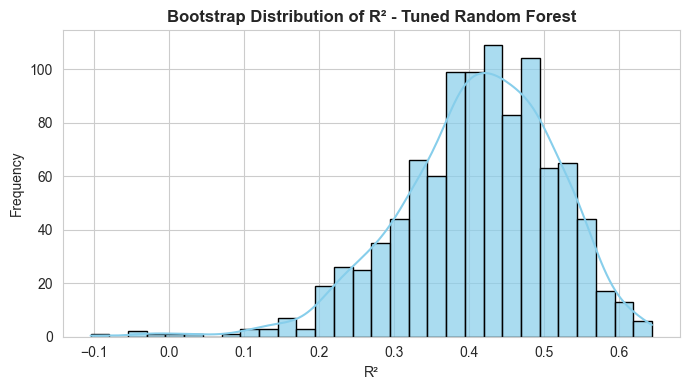

In [121]:
# Bootstrap R² Distribution - Tuned Random Forest

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.histplot(
    rf_boot_results["R2"],
    bins=30,
    kde=True,
    color="skyblue",
    edgecolor="black",
    alpha=0.7
)

plt.title(
    "Bootstrap Distribution of R² - Tuned Random Forest",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("R²")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

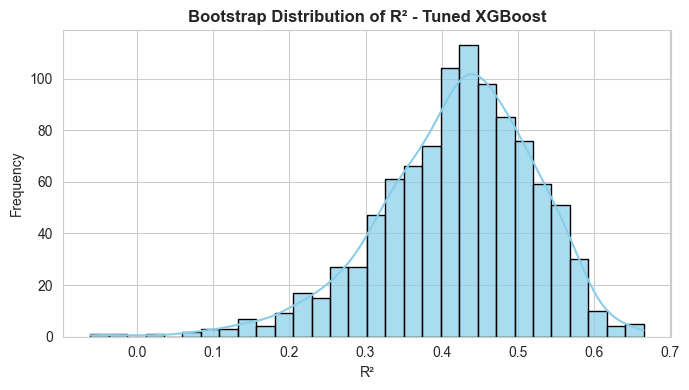

In [122]:
# Bootstrap R² Distribution - Tuned XGBoost

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.histplot(
    xgb_boot_results["R2"],
    bins=30,
    kde=True,
    color="skyblue",
    edgecolor="black",
    alpha=0.7
)

plt.title(
    "Bootstrap Distribution of R² - Tuned XGBoost",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("R²")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Bootstrap Distribution of RMSE

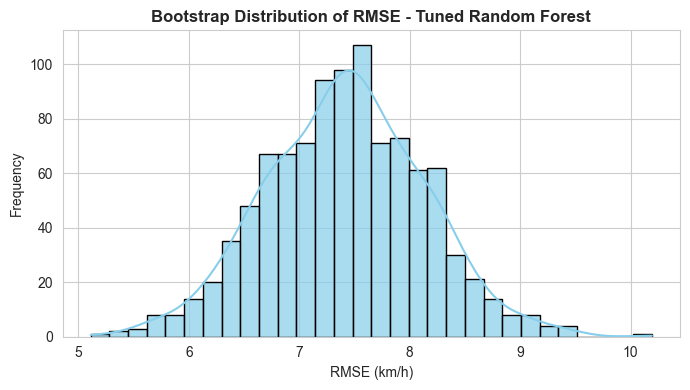

In [123]:
# Bootstrap RMSE Distribution - Tuned Random Forest

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.histplot(
    rf_boot_results["RMSE"],
    bins=30,
    kde=True,
    color="skyblue",
    edgecolor="black",
    alpha=0.7
)

plt.title(
    "Bootstrap Distribution of RMSE - Tuned Random Forest",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("RMSE (km/h)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

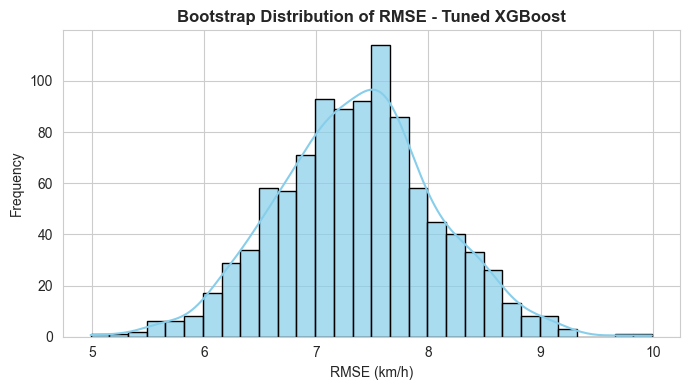

In [124]:
# Bootstrap RMSE Distribution - Tuned XGBoost

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))

sns.histplot(
    xgb_boot_results["RMSE"],
    bins=30,
    kde=True,
    color="skyblue",
    edgecolor="black",
    alpha=0.7
)

plt.title(
    "Bootstrap Distribution of RMSE - Tuned XGBoost",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("RMSE (km/h)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Partial Dependence Plots (PDP) for Tuned Random Forest

Import Required Libraries

In [125]:
# Partial Dependence Plot (PDP) Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.inspection import PartialDependenceDisplay

# Use already trained Tuned Random Forest
rf_unscaled = best_rf

# Display best hyperparameters
print("Best RF Parameters:", grid_rf.best_params_)

# Check feature names
print("\nInput Features:")
print(X_train.columns.tolist())

Best RF Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}

Input Features:
['Gradient', 'Radius of Curve', 'Carriageway Width', 'Average Shoulder Width', 'IRI']


PDP for Gradient

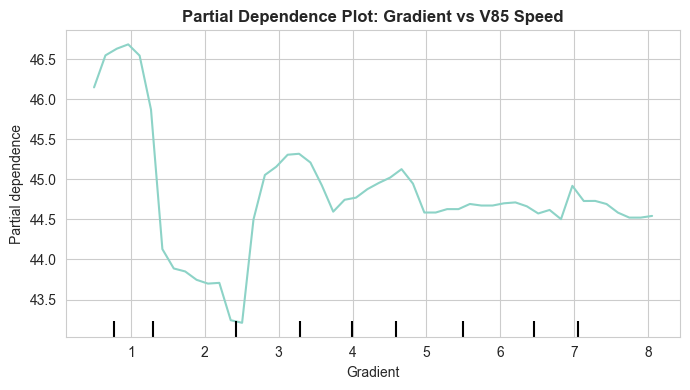

In [126]:
# Partial Dependence Plot: Gradient

fig, ax = plt.subplots(figsize=(7, 4))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=["Gradient"],
    grid_resolution=50,
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence Plot: Gradient vs V85 Speed",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Gradient (%)")
ax.set_ylabel("Predicted V85 Speed (km/h)")

plt.tight_layout()
plt.show()

PDP for Radius of Curve

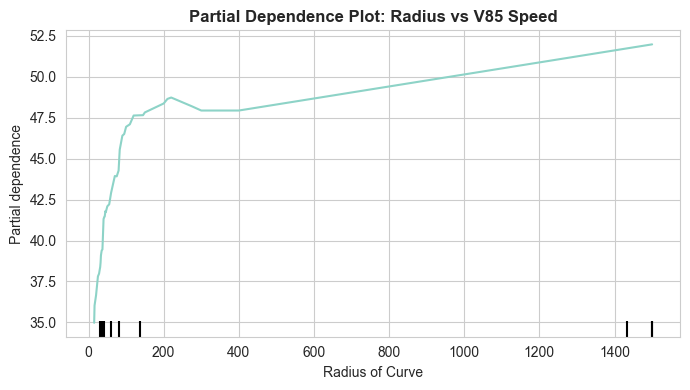

In [127]:
# Partial Dependence Plot: Radius of Curve

fig, ax = plt.subplots(figsize=(7, 4))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=["Radius of Curve"],
    grid_resolution=50,
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence Plot: Radius vs V85 Speed",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Radius of Curve (m)")
ax.set_ylabel("Predicted V85 Speed (km/h)")

plt.tight_layout()
plt.show()

PDP for Carriageway Width

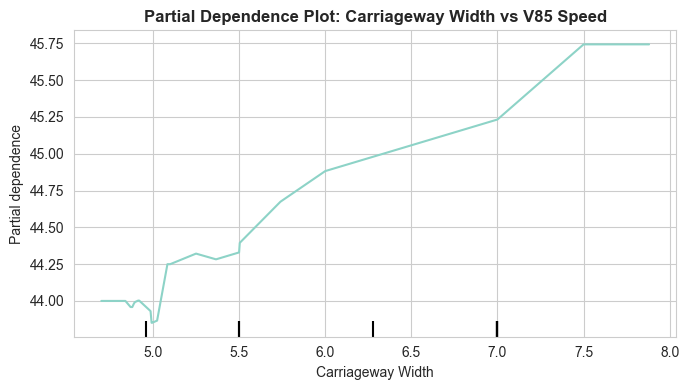

In [128]:
# Partial Dependence Plot: Carriageway Width

fig, ax = plt.subplots(figsize=(7, 4))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=["Carriageway Width"],
    grid_resolution=50,
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence Plot: Carriageway Width vs V85 Speed",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Carriageway Width (m)")
ax.set_ylabel("Predicted V85 Speed (km/h)")

plt.tight_layout()
plt.show()

PDP for Average Shoulder Width

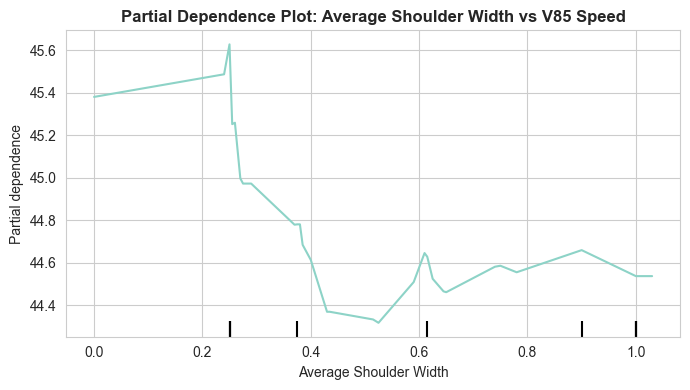

In [129]:
# Partial Dependence Plot: Average Shoulder Width

fig, ax = plt.subplots(figsize=(7, 4))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=["Average Shoulder Width"],
    grid_resolution=50,
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence Plot: Average Shoulder Width vs V85 Speed",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Average Shoulder Width (m)")
ax.set_ylabel("Predicted V85 Speed (km/h)")

plt.tight_layout()
plt.show()

PDP for IRI

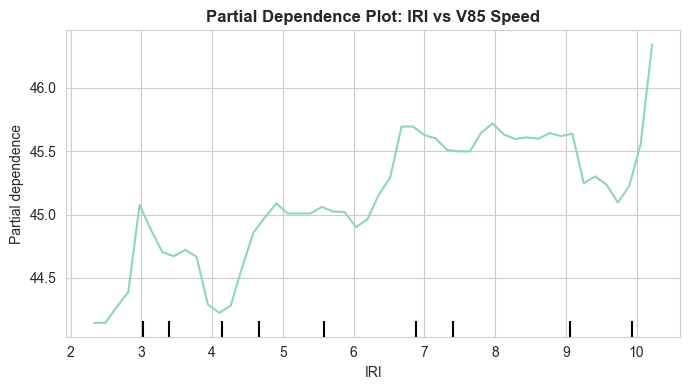

In [130]:
# Partial Dependence Plot: IRI

fig, ax = plt.subplots(figsize=(7, 4))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=["IRI"],
    grid_resolution=50,
    method="brute",
    ax=ax
)

ax.set_title(
    "Partial Dependence Plot: IRI vs V85 Speed",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("IRI (m/km)")
ax.set_ylabel("Predicted V85 Speed (km/h)")

plt.tight_layout()
plt.show()

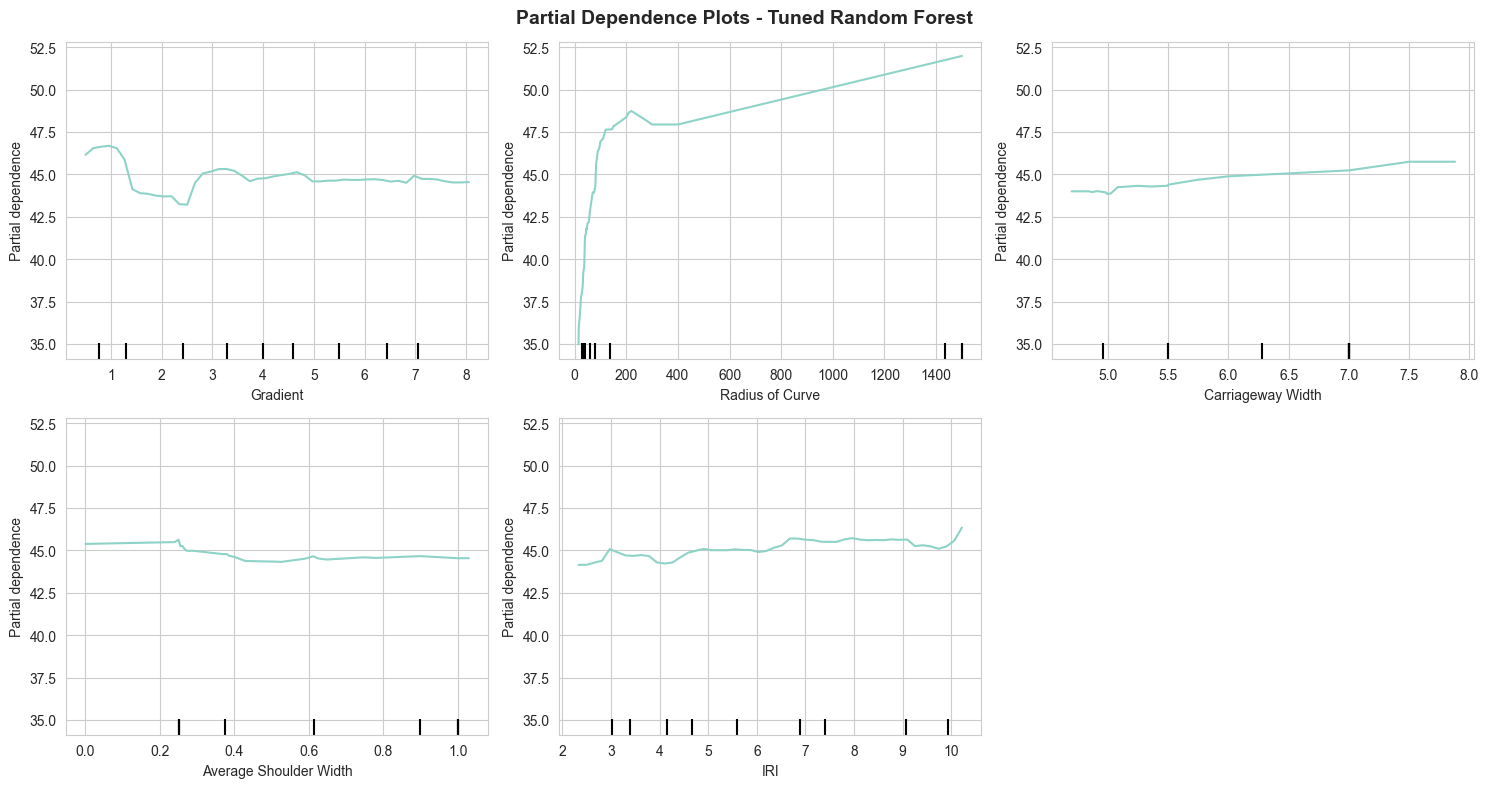

In [131]:
# Combined Partial Dependence Plots for All Five Variables

features = [
    "Gradient",
    "Radius of Curve",
    "Carriageway Width",
    "Average Shoulder Width",
    "IRI"
]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

PartialDependenceDisplay.from_estimator(
    rf_unscaled,
    X_train,
    features=features,
    grid_resolution=50,
    method="brute",
    ax=ax.ravel()[:5]
)

# Remove empty subplot
fig.delaxes(ax[1, 2])

plt.suptitle(
    "Partial Dependence Plots - Tuned Random Forest",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Sensitivity Analysis of Tangent Radius

In [132]:
# ============================================================
# TANGENT RADIUS SENSITIVITY ANALYSIS
# MLR + FOUR TUNED MACHINE LEARNING MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

sns.set_style("whitegrid")

Identify Tangent Sections

In [133]:
# ============================================================
# STEP 2: IDENTIFY TANGENT SECTIONS
# ============================================================

tangent_mask = (
    df["Radius of Curve"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["infinity", "inf", "+inf", "∞"])
)

# Match mask to model dataset
tangent_mask = tangent_mask.reindex(X.index)

# Check dataset
print("Total Observations:", len(X))
print("Tangent Sections:", tangent_mask.sum())
print("Curved Sections:", (~tangent_mask).sum())

# Verify data and tangent identification
assert len(X) == 165, "Expected 165 observations."
assert tangent_mask.notna().all(), "Index mismatch detected."
assert tangent_mask.sum() == 45, "Tangent section count does not match."

print("\nTangent sections identified successfully.")

Total Observations: 165
Tangent Sections: 45
Curved Sections: 120

Tangent sections identified successfully.


DEFINE TANGENT RADIUS SCENARIOS

In [134]:
# ============================================================
# STEP 3: DEFINE TANGENT RADIUS SCENARIOS
# ============================================================

tangent_radius_values = [1000, 1500, 2000]

print("Sensitivity Analysis Scenarios:")

for radius in tangent_radius_values:
    print(f"Tangent Radius = {radius} m")

Sensitivity Analysis Scenarios:
Tangent Radius = 1000 m
Tangent Radius = 1500 m
Tangent Radius = 2000 m


Define the Five Selected Models

In [135]:
# ============================================================
# STEP 4: DEFINE FIVE SELECTED MODELS
# ============================================================

models_sensitivity = {

    "MLR": mlr,

    "Tuned Random Forest": best_rf,

    "Tuned XGBoost": best_xgb,

    "Tuned SVR": best_svr,

    "Tuned ANN": best_ann
}

# Verify tuned SVR and ANN contain scaling pipelines

assert isinstance(best_svr, Pipeline), (
    "Tuned SVR must contain a scaling pipeline."
)

assert isinstance(best_ann, Pipeline), (
    "Tuned ANN must contain a scaling pipeline."
)

# Display selected models

print("Models Selected for Sensitivity Analysis:\n")

for i, model_name in enumerate(models_sensitivity.keys(), 1):
    print(f"{i}. {model_name}")

Models Selected for Sensitivity Analysis:

1. MLR
2. Tuned Random Forest
3. Tuned XGBoost
4. Tuned SVR
5. Tuned ANN


Run the Automated Sensitivity Analysis

In [136]:
# ============================================================
# STEP 5: AUTOMATED TANGENT RADIUS SENSITIVITY ANALYSIS
# ============================================================

sensitivity_results = []

# Store fitted models for additional analysis
fitted_sensitivity_models = {}

# Loop through tangent radius scenarios

for tangent_radius in tangent_radius_values:

    print("\n" + "=" * 60)
    print(f"TANGENT RADIUS = {tangent_radius} m")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. Create scenario dataset
    # --------------------------------------------------------

    X_sens = X.copy()

    # Change radius ONLY for tangent sections

    X_sens.loc[
        tangent_mask,
        "Radius of Curve"
    ] = tangent_radius

    # --------------------------------------------------------
    # 2. Preserve original training and testing observations
    # --------------------------------------------------------

    X_train_sens = X_sens.loc[X_train.index].copy()

    X_test_sens = X_sens.loc[X_test.index].copy()

    # --------------------------------------------------------
    # 3. Train and evaluate each model
    # --------------------------------------------------------

    for model_name, model in models_sensitivity.items():

        print(f"Training: {model_name}")

        # Create fresh model with original hyperparameters

        model_sens = clone(model)

        # Train model

        model_sens.fit(X_train_sens, y_train)

        # Store fitted model

        fitted_sensitivity_models[
            (tangent_radius, model_name)
        ] = model_sens

        # Predictions

        y_train_pred = model_sens.predict(X_train_sens)

        y_test_pred = model_sens.predict(X_test_sens)

        # ----------------------------------------------------
        # 4. Calculate evaluation metrics
        # ----------------------------------------------------

        # R²

        train_r2 = r2_score(
            y_train, y_train_pred
        )

        test_r2 = r2_score(
            y_test, y_test_pred
        )

        # RMSE

        train_rmse = np.sqrt(
            mean_squared_error(y_train, y_train_pred)
        )

        test_rmse = np.sqrt(
            mean_squared_error(y_test, y_test_pred)
        )

        # MAE

        train_mae = mean_absolute_error(
            y_train, y_train_pred
        )

        test_mae = mean_absolute_error(
            y_test, y_test_pred
        )

        # ----------------------------------------------------
        # 5. Store results
        # ----------------------------------------------------

        sensitivity_results.append({

            "Model": model_name,

            "Tangent Radius (m)": tangent_radius,

            "Training R2": train_r2,

            "Testing R2": test_r2,

            "Training RMSE": train_rmse,

            "Testing RMSE": test_rmse,

            "Training MAE": train_mae,

            "Testing MAE": test_mae

        })

# ------------------------------------------------------------
# 6. Create results table
# ------------------------------------------------------------

sensitivity_table = pd.DataFrame(
    sensitivity_results
)

# Arrange results

sensitivity_table = sensitivity_table.sort_values(
    by=["Model", "Tangent Radius (m)"]
).reset_index(drop=True)

# Display results

display(sensitivity_table.round(4))


TANGENT RADIUS = 1000 m
Training: MLR
Training: Tuned Random Forest
Training: Tuned XGBoost
Training: Tuned SVR
Training: Tuned ANN

TANGENT RADIUS = 1500 m
Training: MLR
Training: Tuned Random Forest
Training: Tuned XGBoost
Training: Tuned SVR
Training: Tuned ANN

TANGENT RADIUS = 2000 m
Training: MLR
Training: Tuned Random Forest
Training: Tuned XGBoost
Training: Tuned SVR
Training: Tuned ANN


,Model,Tangent Radius (m),Training R2,Testing R2,Training RMSE,Testing RMSE,Training MAE,Testing MAE
0,MLR,1000,0.4331,0.2810,7.3748,6.4480,5.8013,5.3396
1,MLR,1500,0.4238,0.2457,7.4355,6.6042,5.8476,5.4931
2,MLR,2000,0.4187,0.2281,7.4680,6.6810,5.8769,5.5634
3,Tuned ANN,1000,0.5163,0.2120,6.8126,6.7503,5.2586,5.4520
4,Tuned ANN,1500,0.5020,0.1421,6.9120,7.0432,5.3194,5.7179
5,Tuned ANN,2000,0.4951,0.1038,6.9596,7.1986,5.3564,5.8332
6,Tuned Random Forest,1000,0.7358,0.5968,5.0344,4.8285,3.9157,3.7643
7,Tuned Random Forest,1500,0.7358,0.5968,5.0344,4.8285,3.9157,3.7643
8,Tuned Random Forest,2000,0.7358,0.5968,5.0344,4.8285,3.9157,3.7643
9,Tuned SVR,1000,0.4577,0.2123,7.2128,6.7491,5.3685,5.4354


Result Table

In [137]:
# ============================================================
# STEP 6: FINAL SENSITIVITY RESULTS TABLE
# ============================================================

sensitivity_final = sensitivity_table[
    [
        "Model",
        "Tangent Radius (m)",
        "Testing R2",
        "Testing RMSE",
        "Testing MAE"
    ]
].copy()

# Round results

sensitivity_final[
    ["Testing R2", "Testing RMSE", "Testing MAE"]
] = sensitivity_final[
    ["Testing R2", "Testing RMSE", "Testing MAE"]
].round(3)

# Display results

display(sensitivity_final)

,Model,Tangent Radius (m),Testing R2,Testing RMSE,Testing MAE
0,MLR,1000,0.281,6.448,5.340
1,MLR,1500,0.246,6.604,5.493
2,MLR,2000,0.228,6.681,5.563
3,Tuned ANN,1000,0.212,6.750,5.452
4,Tuned ANN,1500,0.142,7.043,5.718
5,Tuned ANN,2000,0.104,7.199,5.833
6,Tuned Random Forest,1000,0.597,4.829,3.764
7,Tuned Random Forest,1500,0.597,4.829,3.764
8,Tuned Random Forest,2000,0.597,4.829,3.764
9,Tuned SVR,1000,0.212,6.749,5.435


RMSE SENSITIVITY COMPARISON

In [138]:
# ============================================================
# STEP 7: RMSE SENSITIVITY COMPARISON
# ============================================================

rmse_sensitivity = sensitivity_table.pivot(
    index="Model",
    columns="Tangent Radius (m)",
    values="Testing RMSE"
)

# Arrange model order

rmse_sensitivity = rmse_sensitivity.reindex(
    list(models_sensitivity.keys())
)

# Arrange radius order

rmse_sensitivity = rmse_sensitivity[
    [1000, 1500, 2000]
]

# Rename columns

rmse_sensitivity.columns = [
    "RMSE (1000 m)",
    "RMSE (1500 m)",
    "RMSE (2000 m)"
]

# Display results

display(rmse_sensitivity.round(3))

,RMSE (1000 m),RMSE (1500 m),RMSE (2000 m)
Model,,,
MLR,6.448,6.604,6.681
Tuned Random Forest,4.829,4.829,4.829
Tuned XGBoost,5.127,5.127,5.127
Tuned SVR,6.749,6.879,6.963
Tuned ANN,6.750,7.043,7.199


R² SENSITIVITY COMPARISON

In [139]:
# ============================================================
# STEP 8: R² SENSITIVITY COMPARISON
# ============================================================

r2_sensitivity = sensitivity_table.pivot(
    index="Model",
    columns="Tangent Radius (m)",
    values="Testing R2"
)

# Arrange model order

r2_sensitivity = r2_sensitivity.reindex(
    list(models_sensitivity.keys())
)

# Arrange radius order

r2_sensitivity = r2_sensitivity[
    [1000, 1500, 2000]
]

# Rename columns

r2_sensitivity.columns = [
    "R2 (1000 m)",
    "R2 (1500 m)",
    "R2 (2000 m)"
]

# Display results

display(r2_sensitivity.round(3))

,R2 (1000 m),R2 (1500 m),R2 (2000 m)
Model,,,
MLR,0.281,0.246,0.228
Tuned Random Forest,0.597,0.597,0.597
Tuned XGBoost,0.545,0.545,0.545
Tuned SVR,0.212,0.182,0.161
Tuned ANN,0.212,0.142,0.104


CHANGE IN RMSE RELATIVE TO 1500 m

In [140]:
# ============================================================
# STEP 9: CHANGE IN RMSE RELATIVE TO 1500 m
# ============================================================

rmse_change = rmse_sensitivity.copy()

# Change for 1000 m

rmse_change["Change (1000 - 1500)"] = (
    rmse_change["RMSE (1000 m)"]
    - rmse_change["RMSE (1500 m)"]
)

# Change for 2000 m

rmse_change["Change (2000 - 1500)"] = (
    rmse_change["RMSE (2000 m)"]
    - rmse_change["RMSE (1500 m)"]
)

# Display results

display(rmse_change.round(4))

,RMSE (1000 m),RMSE (1500 m),RMSE (2000 m),Change (1000 - 1500),Change (2000 - 1500)
Model,,,,,
MLR,6.4480,6.6042,6.6810,-0.1562,0.0768
Tuned Random Forest,4.8285,4.8285,4.8285,0.0000,0.0000
Tuned XGBoost,5.1275,5.1275,5.1275,0.0000,0.0000
Tuned SVR,6.7491,6.8793,6.9632,-0.1302,0.0839
Tuned ANN,6.7503,7.0432,7.1986,-0.2929,0.1555


OVERALL RMSE SENSITIVITY

In [141]:
# ============================================================
# STEP 10: OVERALL RMSE SENSITIVITY
# ============================================================

rmse_variation = pd.DataFrame({

    "Model": rmse_sensitivity.index,

    "RMSE (1000 m)": rmse_sensitivity[
        "RMSE (1000 m)"
    ].values,

    "RMSE (1500 m)": rmse_sensitivity[
        "RMSE (1500 m)"
    ].values,

    "RMSE (2000 m)": rmse_sensitivity[
        "RMSE (2000 m)"
    ].values

})

# Calculate RMSE range

rmse_variation["RMSE Variation"] = (
    rmse_variation[
        ["RMSE (1000 m)", "RMSE (1500 m)", "RMSE (2000 m)"]
    ].max(axis=1)
    -
    rmse_variation[
        ["RMSE (1000 m)", "RMSE (1500 m)", "RMSE (2000 m)"]
    ].min(axis=1)
)

# Sort by lowest variation

rmse_variation = rmse_variation.sort_values(
    by="RMSE Variation",
    ascending=True
).reset_index(drop=True)

# Display results

display(rmse_variation.round(4))

,Model,RMSE (1000 m),RMSE (1500 m),RMSE (2000 m),RMSE Variation
0,Tuned Random Forest,4.8285,4.8285,4.8285,0.0000
1,Tuned XGBoost,5.1275,5.1275,5.1275,0.0000
2,Tuned SVR,6.7491,6.8793,6.9632,0.2141
3,MLR,6.4480,6.6042,6.6810,0.2330
4,Tuned ANN,6.7503,7.0432,7.1986,0.4484


TANGENT RADIUS VS TESTING RMSE

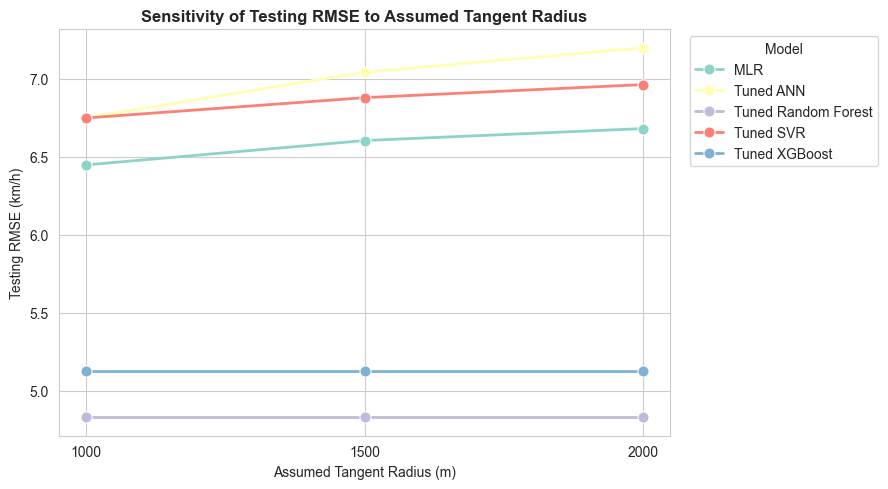

In [142]:
# ============================================================
# STEP 11: TANGENT RADIUS VS TESTING RMSE
# ============================================================

sns.set_style("whitegrid")

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=sensitivity_table,
    x="Tangent Radius (m)",
    y="Testing RMSE",
    hue="Model",
    marker="o",
    markersize=8,
    linewidth=2
)

plt.title(
    "Sensitivity of Testing RMSE to Assumed Tangent Radius",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Assumed Tangent Radius (m)")
plt.ylabel("Testing RMSE (km/h)")

plt.xticks([1000, 1500, 2000])

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "Tangent_Radius_RMSE_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

TANGENT RADIUS VS TESTING R²

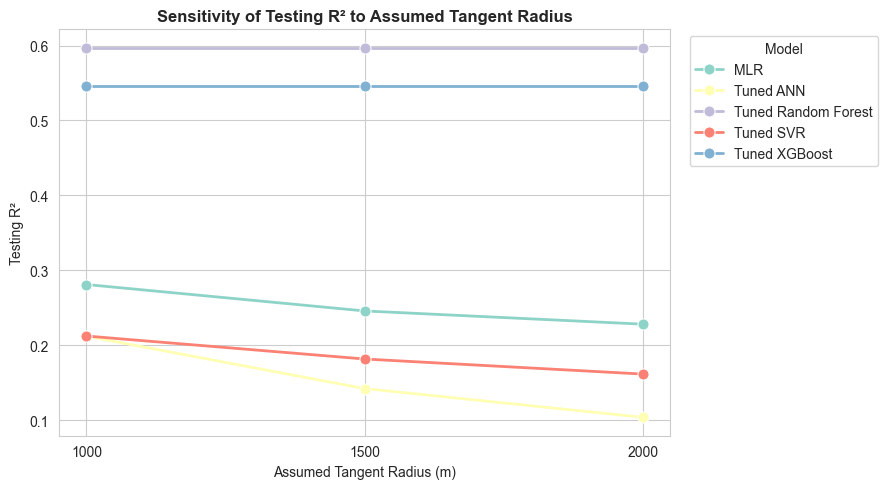

In [143]:
# ============================================================
# STEP 12: TANGENT RADIUS VS TESTING R²
# ============================================================

sns.set_style("whitegrid")

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=sensitivity_table,
    x="Tangent Radius (m)",
    y="Testing R2",
    hue="Model",
    marker="o",
    markersize=8,
    linewidth=2
)

plt.title(
    "Sensitivity of Testing R² to Assumed Tangent Radius",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel("Assumed Tangent Radius (m)")
plt.ylabel("Testing R²")

plt.xticks([1000, 1500, 2000])

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "Tangent_Radius_R2_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

VERIFY ORIGINAL 1500 m MODEL RESULTS

In [144]:
# ============================================================
# STEP 13: VERIFY ORIGINAL 1500 m MODEL RESULTS
# ============================================================

# Extract sensitivity results for 1500 m

baseline_sensitivity = sensitivity_table[
    sensitivity_table["Tangent Radius (m)"] == 1500
][
    ["Model", "Testing R2", "Testing RMSE", "Testing MAE"]
].copy()

# Rename columns

baseline_sensitivity = baseline_sensitivity.rename(
    columns={
        "Testing R2": "Sensitivity R2",
        "Testing RMSE": "Sensitivity RMSE",
        "Testing MAE": "Sensitivity MAE"
    }
)

# Merge with existing model comparison

verification_table = pd.merge(
    master_table[
        ["Model", "R2", "RMSE", "MAE"]
    ],
    baseline_sensitivity,
    on="Model",
    how="inner"
)

# Calculate differences

verification_table["R2 Difference"] = (
    verification_table["Sensitivity R2"]
    - verification_table["R2"]
)

verification_table["RMSE Difference"] = (
    verification_table["Sensitivity RMSE"]
    - verification_table["RMSE"]
)

verification_table["MAE Difference"] = (
    verification_table["Sensitivity MAE"]
    - verification_table["MAE"]
)

# Display results

display(verification_table.round(4))

,Model,R2,RMSE,MAE,Sensitivity R2,Sensitivity RMSE,Sensitivity MAE,R2 Difference,RMSE Difference,MAE Difference
0,Tuned Random Forest,0.597,4.829,3.764,0.5968,4.8285,3.7643,-0.0002,-0.0005,0.0003
1,Tuned XGBoost,0.545,5.127,4.126,0.5453,5.1275,4.1258,0.0003,0.0005,-0.0002
2,MLR,0.246,6.604,5.493,0.2457,6.6042,5.4931,-0.0003,0.0002,0.0001
3,Tuned SVR,0.182,6.879,5.559,0.1816,6.8793,5.5586,-0.0004,0.0003,-0.0004
4,Tuned ANN,0.142,7.043,5.718,0.1421,7.0432,5.7179,0.0001,0.0002,-0.0001


Exporting the Outputs

In [145]:
#from pathlib import Path

# Location of export script
#script_path = Path(
 #   r"D:\MSC THESIS AAVAS\AFTER MID DEFENSE\FINAL OUTPUT\export_v85_report_outputs.py"
#)

# Verify that the file exists
#print("Script found:", script_path.is_file())

# Run the export script
#if script_path.is_file():

 #   print("\nStarting export of all figures and tables...\n")

  #  exec(
   #     compile(
    #        script_path.read_text(encoding="utf-8"),
     #       str(script_path),
      #      "exec"
       # ),
       # globals()
  #  )

#else:
 #   print("\nScript is still missing.")
  #  print("Check the filename and folder location.")

In [146]:
# ============================================================
# RMSE-BASED HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from IPython.display import display

In [147]:
# ============================================================
# STEP 2: RANDOM FOREST - RMSE-BASED TUNING
# ============================================================

grid_rf_rmse = GridSearchCV(
    estimator=clone(grid_rf.estimator),

    param_grid=grid_rf.param_grid,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=1,

    refit=True
)

# Fit using the original training data
grid_rf_rmse.fit(X_train, y_train)

# Extract best model
best_rf_rmse = grid_rf_rmse.best_estimator_

print("RANDOM FOREST - RMSE TUNING")

print("\nBest Hyperparameters:")
print(grid_rf_rmse.best_params_)

print(
    "\nBest Cross-Validation RMSE:",
    round(-grid_rf_rmse.best_score_, 4)
)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
RANDOM FOREST - RMSE TUNING

Best Hyperparameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}

Best Cross-Validation RMSE: 6.9285


In [149]:
# ============================================================
# STEP 3: XGBOOST - RMSE-BASED TUNING
# ============================================================

grid_xgb_rmse = GridSearchCV(
    estimator=clone(grid_xgb.estimator),

    param_grid=grid_xgb.param_grid,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=1,

    refit=True
)

# Fit model
grid_xgb_rmse.fit(X_train, y_train)

# Extract best model
best_xgb_rmse = grid_xgb_rmse.best_estimator_

print("XGBOOST - RMSE TUNING")

print("\nBest Hyperparameters:")
print(grid_xgb_rmse.best_params_)

print(
    "\nBest Cross-Validation RMSE:",
    round(-grid_xgb_rmse.best_score_, 4)
)

Fitting 5 folds for each of 162 candidates, totalling 810 fits
XGBOOST - RMSE TUNING

Best Hyperparameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}

Best Cross-Validation RMSE: 6.898


In [150]:
Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])
# ============================================================
# STEP 4: SVR - RMSE-BASED TUNING
# ============================================================

grid_svr_rmse = GridSearchCV(
    estimator=clone(grid_svr.estimator),

    param_grid=grid_svr.param_grid,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=1,

    refit=True
)

# Fit model
grid_svr_rmse.fit(X_train, y_train)

# Extract best model
best_svr_rmse = grid_svr_rmse.best_estimator_

print("SVR - RMSE TUNING")

print("\nBest Hyperparameters:")
print(grid_svr_rmse.best_params_)

print(
    "\nBest Cross-Validation RMSE:",
    round(-grid_svr_rmse.best_score_, 4)
)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
SVR - RMSE TUNING

Best Hyperparameters:
{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

Best Cross-Validation RMSE: 7.6441


In [151]:
# ============================================================
# STEP 5: ANN - RMSE-BASED TUNING
# ============================================================

grid_ann_rmse = GridSearchCV(
    estimator=clone(grid_ann.estimator),

    param_grid=grid_ann.param_grid,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=1,

    refit=True
)

# Fit model
grid_ann_rmse.fit(X_train, y_train)

# Extract best model
best_ann_rmse = grid_ann_rmse.best_estimator_

print("ANN - RMSE TUNING")

print("\nBest Hyperparameters:")
print(grid_ann_rmse.best_params_)

print(
    "\nBest Cross-Validation RMSE:",
    round(-grid_ann_rmse.best_score_, 4)
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
ANN - RMSE TUNING

Best Hyperparameters:
{'ann__activation': 'tanh', 'ann__alpha': 0.01, 'ann__hidden_layer_sizes': (32,), 'ann__learning_rate_init': 0.001}

Best Cross-Validation RMSE: 7.4666


In [152]:
# ============================================================
# STEP 6: COMPARE R2 AND RMSE-BASED TUNING
# ============================================================

tuning_comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "XGBoost",
        "SVR",
        "ANN"
    ],

    "R2-Based Parameters": [
        grid_rf.best_params_,
        grid_xgb.best_params_,
        grid_svr.best_params_,
        grid_ann.best_params_
    ],

    "RMSE-Based Parameters": [
        grid_rf_rmse.best_params_,
        grid_xgb_rmse.best_params_,
        grid_svr_rmse.best_params_,
        grid_ann_rmse.best_params_
    ]
})

display(tuning_comparison)

,Model,R2-Based Parameters,RMSE-Based Parameters
0,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...","{'max_depth': None, 'max_features': 'sqrt', 'm..."
1,XGBoost,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...","{'colsample_bytree': 1.0, 'learning_rate': 0.0..."
2,SVR,"{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__ga...","{'svr__C': 100, 'svr__epsilon': 0.01, 'svr__ga..."
3,ANN,"{'ann__activation': 'tanh', 'ann__alpha': 0.01...","{'ann__activation': 'tanh', 'ann__alpha': 0.01..."


In [153]:
# ============================================================
# STEP 7: TRAINING AND TESTING PERFORMANCE
# ============================================================

models_rmse = {

    "Random Forest": best_rf_rmse,

    "XGBoost": best_xgb_rmse,

    "SVR": best_svr_rmse,

    "ANN": best_ann_rmse
}

results_rmse = []

for model_name, model in models_rmse.items():

    # Training predictions
    y_train_pred = model.predict(X_train)

    # Testing predictions
    y_test_pred = model.predict(X_test)

    # Training metrics
    train_r2 = r2_score(y_train, y_train_pred)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, y_train_pred)
    )

    train_mae = mean_absolute_error(
        y_train, y_train_pred
    )

    # Testing metrics
    test_r2 = r2_score(y_test, y_test_pred)

    test_rmse = np.sqrt(
        mean_squared_error(y_test, y_test_pred)
    )

    test_mae = mean_absolute_error(
        y_test, y_test_pred
    )

    # Store results
    results_rmse.append({

        "Model": model_name,

        "Train R2": train_r2,
        "Test R2": test_r2,

        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,

        "Train MAE": train_mae,
        "Test MAE": test_mae

    })

# Create results table
rmse_tuned_results = pd.DataFrame(results_rmse)

# Sort by testing RMSE
rmse_tuned_results = rmse_tuned_results.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

display(rmse_tuned_results.round(4))

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Random Forest,0.7358,0.5968,5.0344,4.8285,3.9157,3.7643
1,XGBoost,0.7062,0.5453,5.3089,5.1275,4.1120,4.1258
2,SVR,0.4496,0.1816,7.2669,6.8793,5.4137,5.5586
3,ANN,0.5020,0.1421,6.9120,7.0432,5.3194,5.7179


In [154]:
# ============================================================
# STEP 8: COMPARE TWO TUNING CRITERIA
# ============================================================

# Original R2-tuned models
models_r2 = {

    "Random Forest": best_rf,

    "XGBoost": best_xgb,

    "SVR": best_svr,

    "ANN": best_ann
}

# New RMSE-tuned models
models_rmse = {

    "Random Forest": best_rf_rmse,

    "XGBoost": best_xgb_rmse,

    "SVR": best_svr_rmse,

    "ANN": best_ann_rmse
}

comparison_results = []

for model_name in models_r2.keys():

    model_r2 = models_r2[model_name]
    model_rmse = models_rmse[model_name]

    # Previous model predictions
    pred_r2 = model_r2.predict(X_test)

    # New model predictions
    pred_rmse = model_rmse.predict(X_test)

    comparison_results.append({

        "Model": model_name,

        "R2-Tuned Test R2": r2_score(
            y_test, pred_r2
        ),

        "RMSE-Tuned Test R2": r2_score(
            y_test, pred_rmse
        ),

        "R2-Tuned Test RMSE": np.sqrt(
            mean_squared_error(y_test, pred_r2)
        ),

        "RMSE-Tuned Test RMSE": np.sqrt(
            mean_squared_error(y_test, pred_rmse)
        ),

        "R2-Tuned Test MAE": mean_absolute_error(
            y_test, pred_r2
        ),

        "RMSE-Tuned Test MAE": mean_absolute_error(
            y_test, pred_rmse
        )

    })

comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.round(4))

,Model,R2-Tuned Test R2,RMSE-Tuned Test R2,R2-Tuned Test RMSE,RMSE-Tuned Test RMSE,R2-Tuned Test MAE,RMSE-Tuned Test MAE
0,Random Forest,0.5968,0.5968,4.8285,4.8285,3.7643,3.7643
1,XGBoost,0.5453,0.5453,5.1275,5.1275,4.1258,4.1258
2,SVR,0.1816,0.1816,6.8793,6.8793,5.5586,5.5586
3,ANN,0.1421,0.1421,7.0432,7.0432,5.7179,5.7179


In [155]:
# ============================================================
# VERIFY WHETHER R2 AND RMSE SELECTED SAME HYPERPARAMETERS
# ============================================================

import pandas as pd

parameter_check = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "SVR",
        "ANN"
    ],

    "Same Hyperparameters": [
        grid_rf.best_params_ == grid_rf_rmse.best_params_,
        grid_xgb.best_params_ == grid_xgb_rmse.best_params_,
        grid_svr.best_params_ == grid_svr_rmse.best_params_,
        grid_ann.best_params_ == grid_ann_rmse.best_params_
    ]
})

display(parameter_check)

,Model,Same Hyperparameters
0,Random Forest,True
1,XGBoost,True
2,SVR,True
3,ANN,True
